# Tiamat

Esse projeto é de autoria de Beatriz Pessoa de Souza, discente da Ilum Escola de Ciência, CNPEM. Ele foi realizado para a disciplina de Aprendizado de Máquina no 2º semestre, cujo docente é Daniel R. Cassar.

## 1. Introdução

### 1.1 Objetivo

A pergunta do trabalho é: *as características genômicas de um tumor conseguem prever seu grau de infiltração imune?*

Tumores muito infiltrados por leucócitos ("quentes") tendem a responder melhor à imunoterapia com inibidores de checkpoint, enquanto tumores pouco infiltrados ("frios") costumam responder pior. Se o genoma do tumor conseguir prever esse grau de infiltração, isso ajuda a entender o que torna um tumor visível ao sistema imune.

### 1.2 Base de dados

Usei a *PanImmune Feature Matrix* (Tabela S1 de Thorsson et al., 2018): 11.080 pacientes do TCGA (uma linha por paciente) e 64 colunas, com atributos imunológicos e genômicos de 33 tipos de câncer. Os atributos foram medidos e estimados pelos autores do artigo a partir de dados de sequenciamento, expressão gênica e metilação do DNA.

### 1.3 Target

O alvo é a ***Leukocyte Fraction***, a fração de leucócitos presentes no tumor, estimada a partir da metilação do DNA. É a principal medida de "tumor quente versus frio" da base e é contínua, então o problema é de **regressão**. Dos 11.080 pacientes, 10.448 têm valor para o alvo; os 632 sem valor incluem todos os casos de DLBC, LAML e THYM, e por isso restam 30 tipos de câncer.

Descartei duas alternativas. O subtipo imune (*Immune Subtype*, C1 a C6) foi definido no artigo por agrupamento de assinaturas de expressão imune, o que geraria circularidade, além de ter 18% de valores faltantes. A sobrevida global (*OS*) sofre com censura, e a análise de sobrevida adequada não faz parte da disciplina.

### 1.4 Atributos usados

Usei **11 atributos**: 10 numéricos de caracterização genômica do tumor e o tipo de tumor. Após a codificação one-hot do tipo de tumor (30 categorias), o modelo recebe 40 colunas de entrada.

**Carga mutacional**
- **Silent Mutation Rate:** mutações por megabase que não trocam o aminoácido. Não alteram proteínas, então servem como medida de instabilidade genômica geral.
- **Nonsilent Mutation Rate:** mutações por megabase que alteram proteínas. É a base da carga mutacional tumoral (TMB), biomarcador clássico de resposta à imunoterapia: mais proteínas alteradas significam mais fragmentos "estranhos" para o sistema imune reconhecer.

**Neoantígenos e antígenos tumorais**
- **SNV Neoantigens:** número de peptídeos mutados, previstos como apresentáveis às células T, gerados por mutações pontuais.
- **Indel Neoantigens:** o mesmo, para inserções e deleções, que podem gerar peptídeos muito diferentes dos normais.
- **CTA Score:** expressão de antígenos câncer-testículo, normalmente restritos ao testículo e reativados em tumores, o que os torna alvos imunológicos.

**Instabilidade cromossômica**
- **Aneuploidy Score:** número de braços cromossômicos com ganho ou perda.
- **Number of Segments:** número de segmentos de alteração no número de cópias do DNA.
- **Fraction Altered:** fração do genoma com alterações de cópias.
- **Homologous Recombination Defects:** escore de defeito no reparo do DNA por recombinação homóloga.
- **Intratumor Heterogeneity:** heterogeneidade clonal, isto é, quão diferentes são as subpopulações de células dentro do mesmo tumor.

**Contexto**
- **TCGA Study:** tipo de câncer (30 categorias, como BRCA e GBM). O ambiente imune varia muito entre tecidos, e a análise exploratória mostra o quanto o tipo de tumor sozinho explica do alvo.

Esses atributos descrevem o genoma do tumor e não a resposta imune, o que evita que o modelo "descubra" o alvo por circularidade. A direção esperada de cada relação não é óbvia, e a análise exploratória a verifica.

**Atributos não usados.** Removi o ID do paciente; todas as medidas que já descrevem a infiltração imune (frações CIBERSORT, assinaturas de expressão, repertório de TCR e BCR, *TIL Regional Fraction*) e a *Stromal Fraction*, que é derivada da própria fração de leucócitos; e os desfechos clínicos e subtipos, que não fazem parte desta pergunta. Usá-los seria vazamento de informação sobre o alvo.

### 1.5 Baseline

Escolhi o `DummyRegressor`: para qualquer tumor novo, ele prevê a média da fração de leucócitos do conjunto de treino. Como não usa atributo nenhum, ele é a régua mínima, ou seja, um modelo só é útil se for melhor do que ele.

### 1.6 Algoritmos

Escolhi cinco algoritmos com vieses indutivos diferentes, para revelar que tipo de relação existe entre genoma e infiltração imune:

- **Regressão linear polinomial** (aula 3.0, seção bônus): assume que a infiltração é uma soma ponderada dos atributos e, quando o grau do polinômio é maior que 1, também de seus quadrados e produtos (interações). Como a regressão linear comum quase não tem hiperparâmetros a otimizar, combinei-a com seleção de atributos por RFE (aula 8.1), que descarta os atributos menos úteis. O modelo exige normalização.
- **k-NN** (aulas 2.0 e 2.1): previsão local, pela média dos tumores mais parecidos. É sensível à escala e à dimensionalidade.
- **Árvore de decisão** (aula 4.0): aprende regras hierárquicas e captura interações sem exigir normalização, mas tende a sobreajustar.
- **Floresta aleatória** (aula 4.0): reduz o sobreajuste ao fazer a média de várias árvores e fornece a importância dos atributos.
- **Gradient Boosting** (`HistGradientBoostingRegressor`, fora da aula): treina árvores em sequência, cada uma corrigindo o erro das anteriores, o que reduz o viés. É uma extensão natural da floresta e aceita valores faltantes sem imputação.

### 1.7 Estratégia de validação

Separei 20% dos pacientes como conjunto de teste, estratificando pelo tipo de tumor, e só o usei no final, uma única vez. Nos 80% restantes, cada combinação de hiperparâmetros foi avaliada por validação cruzada de 5 partições (as mesmas para todos os algoritmos), com 100 combinações testadas pelo Optuna em cada algoritmo e o RMSE como métrica. Toda transformação (imputação, log, normalização, one-hot, PCA, expansão polinomial e RFE) faz parte do pipeline e é ajustada só nos dados de treino de cada partição.

## 2. Coleta e tratamento de dados

In [1]:
import pandas as pd

df = pd.read_excel("1-s2.0-S1074761318301213-mmc2.xlsx")
df = df.convert_dtypes()
df.head()

,TCGA Participant Barcode,TCGA Study,Immune Subtype,TCGA Subtype,Leukocyte Fraction,Stromal Fraction,Intratumor Heterogeneity,TIL Regional Fraction,Proliferation,Wound Healing,...,T Cells CD8,T Cells Follicular Helper,T Cells gamma delta,T Cells Regulatory Tregs,Lymphocytes,Neutrophils.1,Eosinophils.1,Mast Cells,Dendritic Cells,Macrophages
0,TCGA-01-0639,OV,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,TCGA-02-0007,GBM,<NA>,GBM_LGG.Classic-like,0.04766,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,TCGA-02-0011,GBM,<NA>,GBM_LGG.LGm6-GBM,0.062099,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,TCGA-02-0023,GBM,<NA>,GBM_LGG.,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,TCGA-02-0025,GBM,<NA>,GBM_LGG.,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [2]:
df.shape

(11080, 64)

In [3]:
df.describe(include="all")

,TCGA Participant Barcode,TCGA Study,Immune Subtype,TCGA Subtype,Leukocyte Fraction,Stromal Fraction,Intratumor Heterogeneity,TIL Regional Fraction,Proliferation,Wound Healing,...,T Cells CD8,T Cells Follicular Helper,T Cells gamma delta,T Cells Regulatory Tregs,Lymphocytes,Neutrophils.1,Eosinophils.1,Mast Cells,Dendritic Cells,Macrophages
count,11080,11080,9126,7525,10448.0,9780.0,9780.0,4612.0,9660.0,9660.0,...,9693.0,9693.0,9693.0,9693.0,9693.0,9693.0,9693.0,9693.0,9693.0,9693.0
unique,11080,33,6,98,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
top,TCGA-ZX-AA5X,BRCA,C2,GI.CIN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
freq,1,1087,2591,625,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
mean,NaN,NaN,NaN,NaN,0.207562,0.370045,0.136822,7.431695,-0.121471,0.024598,...,0.118592,0.064617,0.001424,0.028105,0.478308,0.005689,0.00133,0.067694,0.026479,0.4205
std,NaN,NaN,NaN,NaN,0.149967,0.210163,0.157311,8.340754,0.955622,0.236453,...,0.084802,0.052253,0.007643,0.033954,0.16529,0.015305,0.006121,0.066339,0.042871,0.15961
min,NaN,NaN,NaN,NaN,-0.000093,0.0,0.0,0.0,-2.8565,-0.762,...,0.0,0.0,0.0,0.0,0.0305,0.0,0.0,0.0,0.0,0.012018
25%,NaN,NaN,NaN,NaN,0.086738,0.2,0.0175,1.359684,-0.9095,-0.1675,...,0.057451,0.024366,0.0,0.0,0.359353,0.0,0.0,0.021231,0.0,0.305337
50%,NaN,NaN,NaN,NaN,0.17088,0.35,0.08,4.649074,0.14015,0.0285,...,0.100891,0.055695,0.0,0.016571,0.479533,0.0,0.0,0.046485,0.009621,0.408865
75%,NaN,NaN,NaN,NaN,0.295044,0.53,0.21,10.53761,0.674425,0.209,...,0.159613,0.092245,0.0,0.044069,0.596925,0.005222,0.0,0.092739,0.032887,0.52483


**Análise do `describe`:** A base tem 11.080 pacientes com IDs únicos (uma linha por paciente) e 33 tipos de câncer, sendo BRCA o mais frequente (1.087 pacientes). Das colunas categóricas, `Immune Subtype` tem 9.126 valores (seis classes, com C2 a mais comum) e `TCGA Subtype` tem 7.525 (98 valores), ou seja, ambas têm muitos faltantes, e por isso não foram usadas. O alvo, `Leukocyte Fraction`, tem 10.448 valores, média de 0,21, mediana de 0,17 e desvio padrão de 0,15, com máximo de 0,96. A média acima da mediana indica distribuição assimétrica à direita. O mínimo é levemente negativo (−0,0001), o que é ruído da estimativa por metilação, já que uma fração não pode ser negativa, e foi mantido por ser desprezível. Outras colunas, como `Stromal Fraction`, têm contagem menor (9.780), mostrando que cada bloco da base veio de uma análise diferente e tem seus próprios faltantes.

In [4]:
ATRIBUTOS_NUMERICOS = [
    "Silent Mutation Rate",
    "Nonsilent Mutation Rate",
    "SNV Neoantigens",
    "Indel Neoantigens",
    "CTA Score",
    "Aneuploidy Score",
    "Number of Segments",
    "Fraction Altered",
    "Homologous Recombination Defects",
    "Intratumor Heterogeneity",
]
ATRIBUTO_CATEGORICO = "TCGA Study"
ATRIBUTOS = ATRIBUTOS_NUMERICOS + [ATRIBUTO_CATEGORICO]
TARGET = "Leukocyte Fraction"

# 1. Me certificando que cada linha é um paciente diferente (evita vazamento por dados redundantes)
print("IDs de pacientes únicos:", df["TCGA Participant Barcode"].is_unique)

# 2. Pacientes sem valor no alvo não podem ser usados 
sem_alvo = df.loc[df[TARGET].isna(), "TCGA Study"].value_counts()
print(f"\nPacientes removidos por não terem o alvo: {sem_alvo.sum()}")
print("Tipos de câncer sem nenhum paciente com alvo:",
      sorted(set(df["TCGA Study"]) - set(df.loc[df[TARGET].notna(), "TCGA Study"])))

# 3. Mantém só os atributos e o alvo, e converte as colunas numéricas para float64 (o convert_dtypes
#    criou tipos do pandas com <NA>; o scikit-learn trabalha com float e NaN)
df_modelo = df.loc[df[TARGET].notna(), ATRIBUTOS + [TARGET]].copy()
df_modelo[ATRIBUTOS_NUMERICOS + [TARGET]] = df_modelo[ATRIBUTOS_NUMERICOS + [TARGET]].astype("float64")
df_modelo[ATRIBUTO_CATEGORICO] = df_modelo[ATRIBUTO_CATEGORICO].astype(str)
df_modelo = df_modelo.reset_index(drop=True)

print(f"\nDados para o modelo: {df_modelo.shape[0]} pacientes, "
      f"{len(ATRIBUTOS)} atributos, {df_modelo[ATRIBUTO_CATEGORICO].nunique()} tipos de câncer")

# 4. Valores faltantes e escala dos atributos
resumo = df_modelo[ATRIBUTOS_NUMERICOS].describe().T
resumo["faltantes (%)"] = df_modelo[ATRIBUTOS_NUMERICOS].isna().mean() * 100
resumo["assimetria"] = df_modelo[ATRIBUTOS_NUMERICOS].skew() # tive ajuda da IA para descobrir formas de ajustar a assimetria
resumo.round(2)

IDs de pacientes únicos: True

Pacientes removidos por não terem o alvo: 632
Tipos de câncer sem nenhum paciente com alvo: ['DLBC', 'LAML', 'THYM']

Dados para o modelo: 10448 pacientes, 11 atributos, 30 tipos de câncer


,count,mean,std,min,25%,50%,75%,max,faltantes (%),assimetria
Silent Mutation Rate,9627.0,1.88,7.36,0.00,0.22,0.49,1.19,259.00,7.86,15.26
Nonsilent Mutation Rate,9627.0,5.37,21.02,0.00,0.69,1.49,3.49,733.23,7.86,13.65
SNV Neoantigens,8332.0,89.17,402.01,0.00,12.00,26.00,58.00,11244.00,20.25,13.26
Indel Neoantigens,6417.0,95.57,351.14,0.00,3.00,16.00,67.00,6721.00,38.58,9.06
CTA Score,8932.0,2.57,1.38,-0.11,1.56,2.21,3.29,8.22,14.51,1.06
Aneuploidy Score,9973.0,8.89,7.16,0.00,3.00,7.00,14.00,34.00,4.55,0.62
Number of Segments,10129.0,166.59,152.57,23.00,72.00,119.00,206.00,1966.00,3.05,3.52
Fraction Altered,10129.0,0.41,0.32,0.00,0.12,0.35,0.69,1.00,3.05,0.29
Homologous Recombination Defects,9987.0,19.25,17.94,0.00,5.00,14.00,29.00,101.00,4.41,1.18
Intratumor Heterogeneity,9402.0,0.14,0.16,0.00,0.02,0.08,0.21,0.99,10.01,1.51


**O que foi feito e por quê**

1. Confirmei que cada ID aparece uma vez, então não há pacientes repetidos que pudessem cair no treino e no teste ao mesmo tempo (vazamento).
2. Remoção dos pacientes sem alvo (632), pois sem o valor do alvo não é possível treinar nem avaliar um modelo supervisionado. Essa remoção eliminou por completo DLBC, LAML e THYM, e restaram 30 tipos de câncer, o que deve ser lembrado ao interpretar os resultados.
3. Selecionei as colunas e mantive só os 11 atributos escolhidos e o alvo; as demais colunas medem a própria infiltração imune ou são desfechos, e causariam vazamento.
4. **Mantive os valores faltantes**, ou seja, não removi as linhas incompletas, porque isso descartaria 45% dos pacientes (só 54,5% têm os 10 atributos numéricos) e provavelmente enviesaria a amostra, já que os faltantes se concentram em certos tipos de câncer (por exemplo, nenhum paciente de ESCA, OV ou STAD tem o valor de `Indel Neoantigens`). Também não imputei aqui: a imputação (mediana) ficou dentro do pipeline, ajustada só nos dados de treino de cada partição, para não vazar informação do teste.
5. Cinco atributos têm assimetria muito alta (as taxas de mutação, os neoantígenos e o número de segmentos, com valores entre 3,5 e 15), com poucos tumores extremos e muitos valores pequenos. Para os modelos sensíveis à escala (k-NN e regressão linear), apliquei `log(1 + x)` nesses cinco atributos. O `CTA Score` ficou de fora porque tem valores negativos e assimetria baixa. As árvores não precisam da transformação, pois só dependem da ordem dos valores.

In [5]:
from sklearn.model_selection import train_test_split

SEMENTE_ALEATORIA = 42

df_treino, df_teste = train_test_split(
    df_modelo,
    test_size=0.2,
    random_state=SEMENTE_ALEATORIA,
    stratify=df_modelo[ATRIBUTO_CATEGORICO],
)

X_treino = df_treino[ATRIBUTOS]
y_treino = df_treino[TARGET]
X_teste = df_teste[ATRIBUTOS]
y_teste = df_teste[TARGET]

print(f"Treino: {len(df_treino)} pacientes | Teste: {len(df_teste)} pacientes")
print("Menor número de pacientes de um tipo de câncer no treino:",
      df_treino[ATRIBUTO_CATEGORICO].value_counts().min())

Treino: 8358 pacientes | Teste: 2090 pacientes
Menor número de pacientes de um tipo de câncer no treino: 29


Dividi os dados **antes** de qualquer visualização ou transformação: toda a análise exploratória abaixo usa apenas o conjunto de treino, e o conjunto de teste só será aberto na seção de resultados. A divisão é estratificada pelo tipo de tumor, para que todos os tipos apareçam no treino e no teste na mesma proporção. Não usei divisão agrupada (aula 6.1) porque cada linha é um paciente diferente, sem repetições.

**Por que 20% para teste?** A aula 2.2 mostra que a faixa usual na literatura é de 10% a 33%, e que há um compromisso: um teste pequeno demais dá uma estimativa de desempenho pouco confiável, e um teste grande demais tira dados do treino. Com 10.448 pacientes, 20% resulta em 2.090 pacientes no teste, o bastante para estimar o RMSE com pouca incerteza, e deixa 8.358 pacientes para o treino e a validação cruzada. Mesmo assim, alguns tipos de câncer têm poucos pacientes no teste (CHOL tem só 7), o que limita as análises por tipo da seção 5.3.


## 3. Visualização dos dados

### 3.1 Análise do alvo

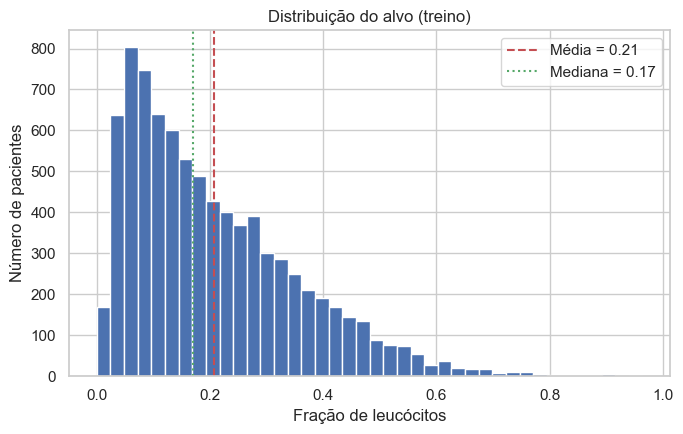

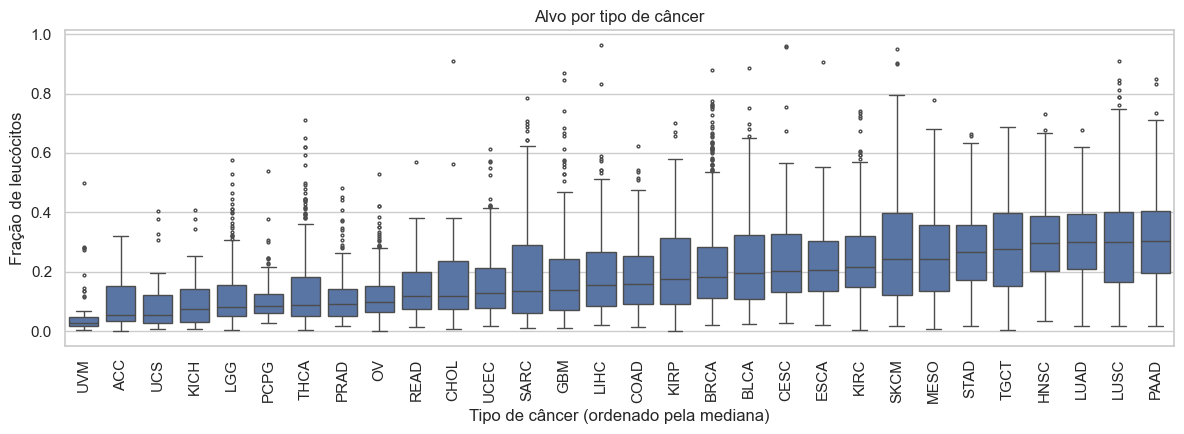

Fração da variância do alvo explicada só pelo tipo de câncer (R²): 0.20
Assimetria do alvo: 1.10


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Distribuição do alvo
fig, eixo = plt.subplots(figsize=(7, 4.5))
eixo.hist(y_treino, bins=40, color="C0")
eixo.axvline(y_treino.mean(), color="C3", ls="--", label=f"Média = {y_treino.mean():.2f}")
eixo.axvline(y_treino.median(), color="C2", ls=":", label=f"Mediana = {y_treino.median():.2f}")
eixo.set(xlabel="Fração de leucócitos", ylabel="Número de pacientes",
         title="Distribuição do alvo (treino)")
eixo.legend()
plt.tight_layout()
plt.show()

# Alvo por tipo de câncer
ordem = df_treino.groupby(ATRIBUTO_CATEGORICO)[TARGET].median().sort_values().index
fig, eixo = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df_treino, x=ATRIBUTO_CATEGORICO, y=TARGET, order=ordem, ax=eixo,
            color="C0", fliersize=2)
eixo.tick_params(axis="x", rotation=90)
eixo.set(xlabel="Tipo de câncer (ordenado pela mediana)", ylabel="Fração de leucócitos",
         title="Alvo por tipo de câncer")
plt.tight_layout()
plt.show()

g = df_treino.groupby(ATRIBUTO_CATEGORICO)[TARGET]
ss_entre = (g.count() * (g.mean() - y_treino.mean()) ** 2).sum()
ss_total = ((y_treino - y_treino.mean()) ** 2).sum()
print(f"Fração da variância do alvo explicada só pelo tipo de câncer (R²): {ss_entre / ss_total:.2f}")
print(f"Assimetria do alvo: {y_treino.skew():.2f}")


# Pedi ajuda da IA para desenvolver o segundo gráfico, perguntei quais métodos eu poderia usar para que eles ficassem da forma que eu queria 

**Análise do alvo.** A distribuição é assimétrica à direita (assimetria de 1,1): a maioria dos tumores tem menos de 30% de leucócitos, com uma cauda que chega a mais de 90%. A média (0,21) fica acima da mediana (0,17), então a média é um previsor ruim para os tumores muito infiltrados, e essa será a limitação do baseline. O boxplot mostra que o tipo de câncer importa muito: as medianas vão de cerca de 0,03 (UVM) a cerca de 0,30 (LUSC, LUAD e PAAD), e o tipo sozinho explica 20% da variância do alvo. Ao mesmo tempo, as caixas são largas, ou seja, a variação **dentro** de cada tipo também é grande, e é nela que os atributos genômicos podem acrescentar algo.

### 3.2 Efeito do log

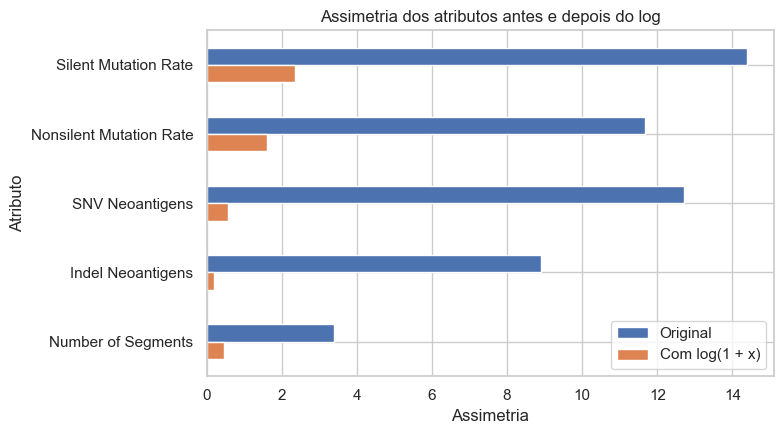

                         Original  Com log(1 + x)
Silent Mutation Rate         14.4             2.4
Nonsilent Mutation Rate      11.7             1.6
SNV Neoantigens              12.7             0.6
Indel Neoantigens             8.9             0.2
Number of Segments            3.4             0.5


In [7]:
ATRIBUTOS_LOG = [
    "Silent Mutation Rate",
    "Nonsilent Mutation Rate",
    "SNV Neoantigens",
    "Indel Neoantigens",
    "Number of Segments",
]

assimetria = pd.DataFrame({
    "Original": [df_treino[a].skew() for a in ATRIBUTOS_LOG],
    "Com log(1 + x)": [np.log1p(df_treino[a].dropna()).skew() for a in ATRIBUTOS_LOG],
}, index=ATRIBUTOS_LOG)

eixo = assimetria.plot.barh(figsize=(8, 4.5), color=["C0", "C1"])
eixo.invert_yaxis()
eixo.set(xlabel="Assimetria", ylabel="Atributo", title="Assimetria dos atributos antes e depois do log")
plt.tight_layout()
plt.show()

print(assimetria.round(1))

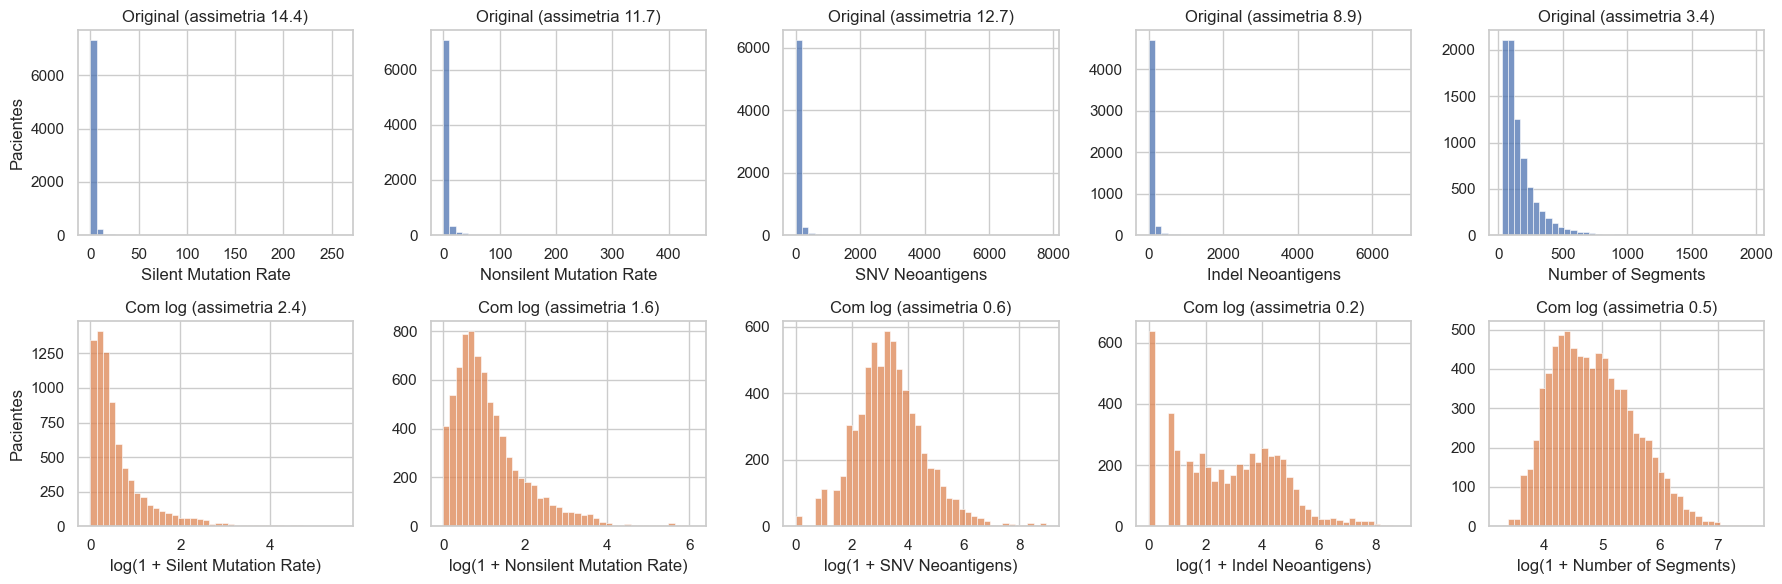

In [8]:
ATRIBUTOS_LOG = [
    "Silent Mutation Rate",
    "Nonsilent Mutation Rate",
    "SNV Neoantigens",
    "Indel Neoantigens",
    "Number of Segments",
]

fig, eixos = plt.subplots(2, 5, figsize=(18, 6))
for j, atributo in enumerate(ATRIBUTOS_LOG):
    sns.histplot(df_treino[atributo].dropna(), bins=40, ax=eixos[0, j], color="C0")
    eixos[0, j].set(xlabel=atributo, ylabel="Pacientes" if j == 0 else "",
                    title=f"Original (assimetria {df_treino[atributo].skew():.1f})")
    transformado = np.log1p(df_treino[atributo].dropna())
    sns.histplot(transformado, bins=40, ax=eixos[1, j], color="C1")
    eixos[1, j].set(xlabel=f"log(1 + {atributo})", ylabel="Pacientes" if j == 0 else "",
                    title=f"Com log (assimetria {transformado.skew():.1f})")
plt.tight_layout()
plt.show()

# Esse gráfico foi feito com apoio da IA para deixar mais claro e detalhado o resultado dos gráficos autorais acima

**Efeito do log.** A transformação reduziu bastante a assimetria (calculada só no treino): Silent Mutation Rate de 14,4 para 2,4; Nonsilent Mutation Rate de 11,7 para 1,6; SNV Neoantigens de 12,7 para 0,6; Indel Neoantigens de 8,9 para 0,2; Number of Segments de 3,4 para 0,5. Na Silent Mutation Rate ainda sobra alguma assimetria, provavelmente por causa de poucos tumores hipermutados, mas ela é bem menor que a original. Sem a transformação, poucos tumores extremos dominariam o cálculo de distâncias do k-NN e dos coeficientes da regressão linear.

### 3.3 Correlação com o alvo e multicolinearidade

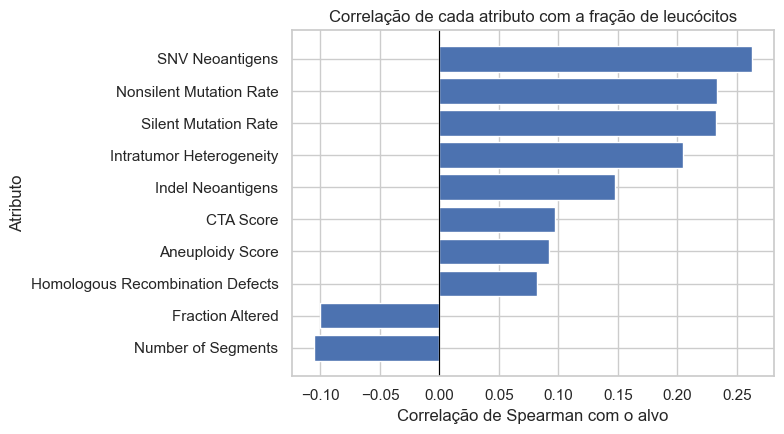

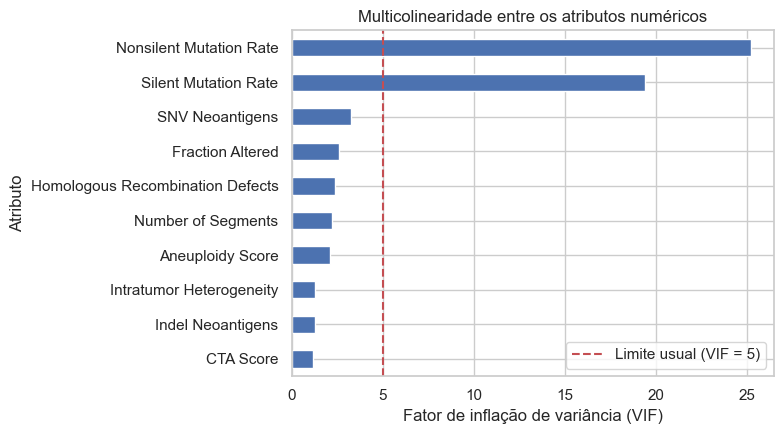

Pares de atributos mais correlacionados (Spearman):
Silent Mutation Rate     Nonsilent Mutation Rate             0.96
Nonsilent Mutation Rate  SNV Neoantigens                     0.96
Silent Mutation Rate     SNV Neoantigens                     0.92
Aneuploidy Score         Fraction Altered                    0.79
Number of Segments       Homologous Recombination Defects    0.76
dtype: float64


In [9]:
dados_corr = df_treino[ATRIBUTOS_NUMERICOS + [TARGET]].copy()
dados_corr[ATRIBUTOS_LOG] = np.log1p(dados_corr[ATRIBUTOS_LOG])
corr = dados_corr.corr(method="spearman")

# Correlação de cada atributo com o alvo
corr_alvo = corr[TARGET].drop(TARGET).sort_values()
fig, eixo = plt.subplots(figsize=(8, 4.5))
eixo.barh(corr_alvo.index, corr_alvo.values, color="C0")
eixo.axvline(0, color="black", lw=0.8)
eixo.set(xlabel="Correlação de Spearman com o alvo", ylabel="Atributo",
         title="Correlação de cada atributo com a fração de leucócitos")
plt.tight_layout()
plt.show()

# Fator de inflação de variância (aula 8.1), calculado pela inversa da matriz de correlação
dados_vif = dados_corr[ATRIBUTOS_NUMERICOS].fillna(dados_corr[ATRIBUTOS_NUMERICOS].median())
vif = pd.Series(np.diag(np.linalg.inv(dados_vif.corr().values)), index=ATRIBUTOS_NUMERICOS)

fig, eixo = plt.subplots(figsize=(8, 4.5))
vif.sort_values().plot.barh(ax=eixo, color="C0")
eixo.axvline(5, color="C3", ls="--", label="Limite usual (VIF = 5)")
eixo.set(xlabel="Fator de inflação de variância (VIF)", ylabel="Atributo",
         title="Multicolinearidade entre os atributos numéricos")
eixo.legend()
plt.tight_layout()
plt.show()

# Pares de atributos mais correlacionados entre si
atributos_corr = corr.loc[ATRIBUTOS_NUMERICOS, ATRIBUTOS_NUMERICOS]
pares = atributos_corr.where(np.triu(np.ones(atributos_corr.shape, dtype=bool), 1)).stack()
print("Pares de atributos mais correlacionados (Spearman):")
print(pares.sort_values(ascending=False).head(5).round(2))

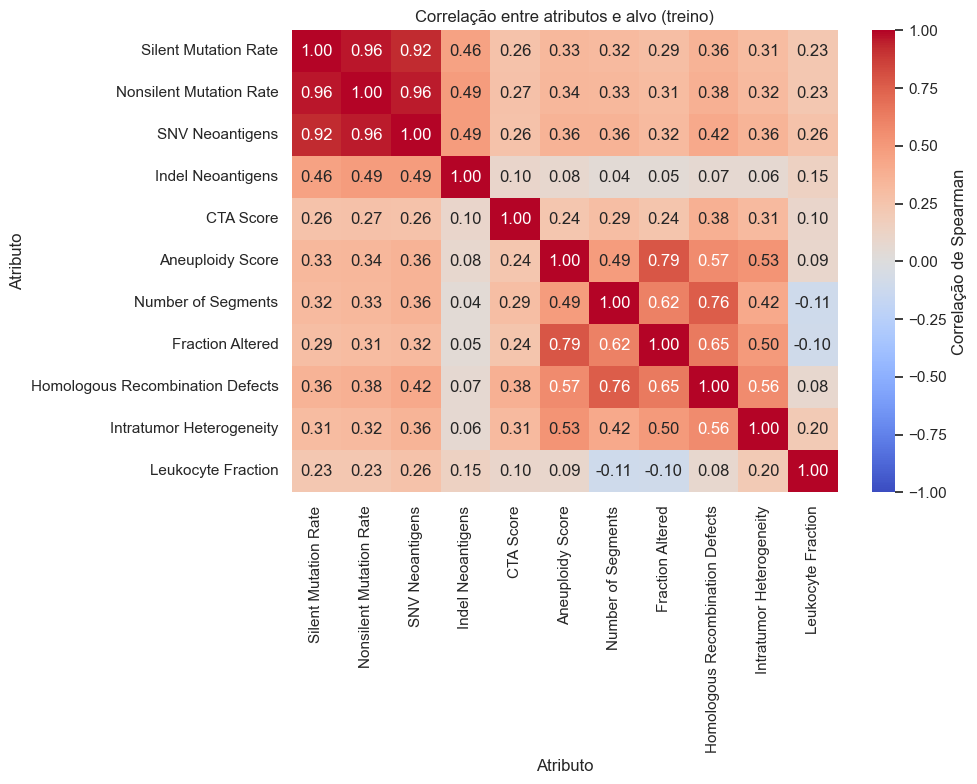

In [10]:
dados_corr = df_treino[ATRIBUTOS_NUMERICOS + [TARGET]].copy()
dados_corr[ATRIBUTOS_LOG] = np.log1p(dados_corr[ATRIBUTOS_LOG])
corr = dados_corr.corr(method="spearman")

fig, eixo = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação de Spearman"}, ax=eixo)
eixo.set(xlabel="Atributo", ylabel="Atributo",
         title="Correlação entre atributos e alvo (treino)")
plt.tight_layout()
plt.show()

# o código estava dando problema e a IA me ajudou a corrigir

**Correlações com o alvo.** Todas são fracas (|ρ| ≤ 0,26): nenhum atributo sozinho prevê bem a infiltração. As associações positivas mais fortes são SNV Neoantigens (0,26), Nonsilent Mutation Rate (0,23), Silent Mutation Rate (0,23) e Intratumor Heterogeneity (0,20), compatíveis com a ideia de que mais mutações e mais neoantígenos dão mais "alvos" ao sistema imune. Number of Segments (−0,11) e Fraction Altered (−0,10) têm correlação negativa, compatível com a hipótese de que instabilidade cromossômica diminui a infiltração. Já o Aneuploidy Score tem correlação levemente **positiva** (0,09), contrária a essa hipótese; a análise por tipo de câncer, mais abaixo, explica isso.

**Multicolinearidade.** As três variáveis de mutação são quase redundantes: Silent e Nonsilent têm correlação de 0,96, Nonsilent e SNV Neoantigens também (0,96), e Silent e SNV, 0,92. Isso produz VIFs de 25,2 (Nonsilent) e 19,4 (Silent), muito acima do limite usual de 5, enquanto os demais atributos ficam em no máximo 3,3. Outro grupo correlacionado é o das alterações de cópias (Aneuploidy e Fraction Altered, 0,79; Number of Segments e HRD, 0,76). A consequência é que os coeficientes de modelos lineares ficam instáveis (o que justifica a seleção de atributos por RFE na regressão linear), e que a importância de cada atributo individual será dividida entre os correlacionados.

### 3.4 Efeito do tipo de câncer sobre as correlações

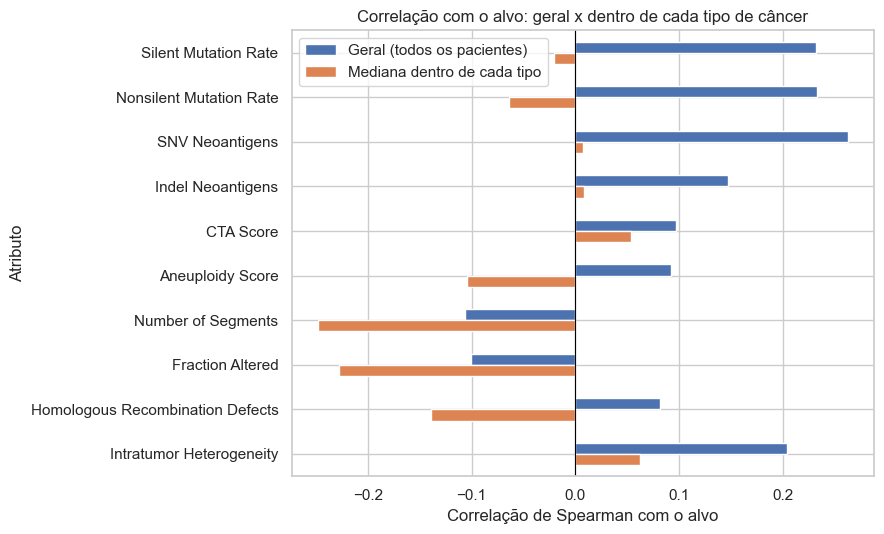

,Geral (todos os pacientes),Mediana dentro de cada tipo,Tipos com correlação positiva (%)
Atributo,,,
Silent Mutation Rate,0.23,-0.02,44.83
Nonsilent Mutation Rate,0.23,-0.06,41.38
SNV Neoantigens,0.26,0.01,51.72
Indel Neoantigens,0.15,0.01,50.00
CTA Score,0.10,0.05,65.52
Aneuploidy Score,0.09,-0.10,31.03
Number of Segments,-0.11,-0.25,13.79
Fraction Altered,-0.10,-0.23,6.90
Homologous Recombination Defects,0.08,-0.14,24.14


In [11]:
linhas = []
for atributo in ATRIBUTOS_NUMERICOS:
    valido = df_treino[atributo].notna()
    rho_geral = df_treino.loc[valido, [atributo, TARGET]].corr(method="spearman").iloc[0, 1]
    rhos = np.array([
        grupo[[atributo, TARGET]].corr(method="spearman").iloc[0, 1]
        for _, grupo in df_treino.groupby(ATRIBUTO_CATEGORICO)
        if grupo[atributo].notna().sum() > 30
    ])
    linhas.append({
        "Atributo": atributo,
        "Geral (todos os pacientes)": rho_geral,
        "Mediana dentro de cada tipo": np.median(rhos),
        "Tipos com correlação positiva (%)": 100 * np.mean(rhos > 0),
    })
comparacao = pd.DataFrame(linhas).set_index("Atributo")

eixo = comparacao[["Geral (todos os pacientes)", "Mediana dentro de cada tipo"]].plot.barh(
    figsize=(9, 5.5), color=["C0", "C1"])
eixo.invert_yaxis()
eixo.axvline(0, color="black", lw=0.8)
eixo.set(xlabel="Correlação de Spearman com o alvo", ylabel="Atributo",
         title="Correlação com o alvo: geral x dentro de cada tipo de câncer")
plt.tight_layout()
plt.show()

comparacao.round(2)

**Efeito do tipo de câncer sobre as correlações.** O gráfico compara, para cada atributo, duas correlações: a geral (todos os pacientes juntos) e a mediana calculada dentro de cada tipo de câncer (só tipos com mais de 30 valores do atributo no treino). As duas contam histórias diferentes, o que é um caso do paradoxo de Simpson:

- **Taxas de mutação e neoantígenos:** a correlação geral é de 0,15 a 0,26, mas dentro de cada tipo a mediana é praticamente zero (entre −0,06 e 0,01). Ou seja, a carga mutacional separa os **tipos** de tumor (tipos muito mutados são, em média, mais infiltrados), mas quase não explica diferenças entre pacientes do mesmo tipo.
- **Number of Segments e Fraction Altered:** a correlação geral é −0,11 e −0,10, mas dentro dos tipos ela fica em −0,25 e −0,23, e o sinal é negativo em 86% e 93% dos tipos. Instabilidade cromossômica está de fato ligada a menos infiltração, e o efeito é mascarado quando os tipos são misturados.
- **Aneuploidy Score e HRD:** a correlação geral é positiva (0,09 e 0,08), mas dentro dos tipos é negativa (−0,10 e −0,14), com sinal positivo em apenas 31% e 24% dos tipos. O sinal positivo geral vem da mistura dos tipos.
- **Intratumor Heterogeneity e CTA Score:** a correlação geral é de 0,20 e 0,10, mas dentro dos tipos cai para 0,06 e 0,05 (sinal positivo em 66% dos tipos nos dois casos). Parte do efeito aparente também vem da diferença entre os tipos.

Isso reforça que o tipo de tumor precisa ser um atributo do modelo, e sugere que modelos capazes de captar interações entre o tipo e os demais atributos (como árvores) podem ter vantagem sobre os lineares.

OBS: essa parte da análise foi sugerida pela IA quando eu pedi para ela corrigir minha análise da base de dados

### 3.5 Análise do PCA

O PCA (Principal Component Analysis) é uma técnica de redução de dimensionalidade que recombina os atributos originais em poucos atributos novos, os componentes principais, perdendo o mínimo possível de informação.

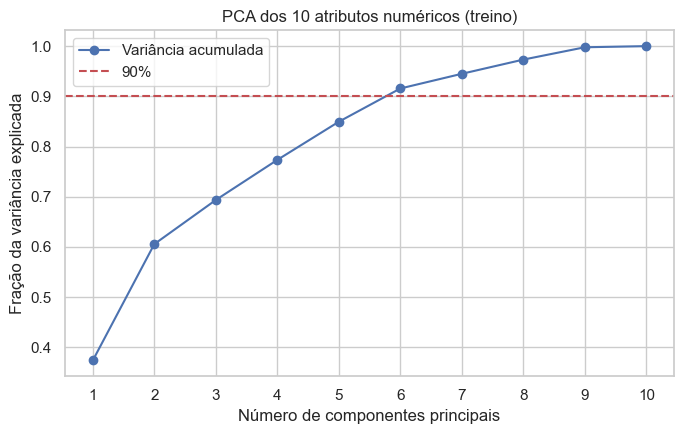

Variância explicada pelo 1º componente: 0.37
Componentes para 90% da variância: 6


In [12]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerico = dados_corr[ATRIBUTOS_NUMERICOS]
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(numerico))
pca = PCA().fit(Z)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)
componentes = np.arange(1, len(variancia_acumulada) + 1)

fig, eixo = plt.subplots(figsize=(7, 4.5))
eixo.plot(componentes, variancia_acumulada, "o-", color="C0", label="Variância acumulada")
eixo.axhline(0.9, color="C3", ls="--", label="90%")
eixo.set(xlabel="Número de componentes principais", ylabel="Fração da variância explicada",
         title="PCA dos 10 atributos numéricos (treino)", xticks=componentes)
eixo.legend()
plt.tight_layout()
plt.show()

print("Variância explicada pelo 1º componente:", round(pca.explained_variance_ratio_[0], 2))
print("Componentes para 90% da variância:", int(np.searchsorted(variancia_acumulada, 0.9) + 1))

**Análise do PCA.** O primeiro componente explica 37% da variância e são necessários 6 componentes para chegar a 92% (e 8 para 97%). Há, portanto, redundância moderada entre os 10 atributos numéricos, concentrada nos dois grupos que vimos na correlação (mutações e alterações de cópias), mas não a ponto de comprimi-los em poucas dimensões. Um ponto importante: variância não é o mesmo que informação sobre o alvo, e um componente pequeno pode ser exatamente o que prevê a infiltração. Por isso o Optuna testou o PCA como opção no k-NN, em vez de eu aplicá-lo por conta própria.

## 4. Desenvolvimento

### 4.1 Baseline

O baseline prevê sempre a média do alvo no treino. Foi avaliado com a mesma validação cruzada dos demais algoritmos.

**Por que 5 partições (`NUM_FOLDS = 5`)?** Com mais partições, cada modelo é treinado com mais dados e a estimativa do erro fica menos pessimista, mas o custo cresce, porque cada partição exige treinar o modelo de novo. Como cada tentativa do Optuna é uma validação cruzada completa, o custo total aqui é de 5 algoritmos × 100 tentativas × 5 partições = 2.500 treinos (com 10 partições seriam 5.000). Com 8.358 pacientes no treino, cada partição de treino tem cerca de 6,7 mil pacientes e cada partição de validação, cerca de 1,7 mil, o que já dá uma estimativa estável do RMSE. É também o valor usado no exemplo guiado de otimização da aula 7.1. O `KFold` embaralha os dados (`shuffle=True`) para que as partições não dependam da ordem das linhas, e a semente fixa garante que todas as tentativas e algoritmos usem as mesmas partições.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

NUM_FOLDS = 5
VALIDACAO_CRUZADA = KFold(NUM_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA)

baseline = DummyRegressor(strategy="mean")
rmse_baseline = -cross_val_score(
    baseline, X_treino, y_treino,
    scoring="neg_root_mean_squared_error", cv=VALIDACAO_CRUZADA,
)

print(f"Baseline: RMSE na validação cruzada = {rmse_baseline.mean():.4f} ± {rmse_baseline.std():.4f}")
print(f"Desvio padrão do alvo no treino      = {y_treino.std():.4f}")

Baseline: RMSE na validação cruzada = 0.1497 ± 0.0046
Desvio padrão do alvo no treino      = 0.1498


**Análise do baseline.** O RMSE do baseline na validação cruzada é 0,1497 ± 0,0046, praticamente igual ao desvio padrão do alvo no treino (0,1498). Isso é esperado: prever sempre a média produz um erro igual ao desvio padrão, e o R² é zero por construção. Esse é o valor a bater, e qualquer algoritmo só é útil se ficar bem abaixo de 0,1497.

### 4.2 Pré-processamento

Antes de treinar qualquer algoritmo, os atributos precisam ser preparados: valores faltantes têm de ser preenchidos (com exceção do Gradient Boosting, que os aceita), atributos em escalas muito diferentes precisam ser padronizados nos algoritmos que dependem de distância ou de coeficientes, e o tipo de câncer, que é um texto, precisa virar números.

Todo o pré-processamento é feito **dentro de pipelines** do scikit-learn. Assim, a mediana usada na imputação e a média e o desvio padrão usados na normalização são calculados só com os dados de treino de cada partição da validação cruzada. Se fossem calculados com todos os dados, informação das partições de validação (ou do teste) vazaria para o treino, o que é o vazamento por pré-processamento visto na aula 6.1.

A função `cria_preprocessador`, definida a seguir, devolve o tratamento adequado a cada grupo de algoritmos:

- **`"escalonado"` (k-NN e regressão linear):** esses modelos dependem da escala dos atributos. Os cinco atributos muito assimétricos (as duas taxas de mutação, os neoantígenos de SNV e de indel e o número de segmentos) passam por `log(1 + x)`, e todos os atributos numéricos passam por imputação pela mediana e normalização (média 0 e desvio padrão 1). Há duas etapas opcionais: o PCA (no k-NN) e a expansão polinomial (na regressão linear).
- **`"arvore"` (árvore de decisão e floresta aleatória):** só imputação pela mediana. Árvores dependem apenas da ordem dos valores, então não precisam de log nem de normalização.
- **`"nativo"` (Gradient Boosting):** os atributos numéricos passam direto, porque o `HistGradientBoostingRegressor` trata valores faltantes sozinho.

Em todos os grupos, o tipo de câncer vira uma coluna 0/1 por categoria (one-hot), e categorias que não aparecerem no treino de uma partição viram zeros, em vez de gerar erro.

O PCA e a expansão polinomial são opcionais porque é nas seções seguintes que se decide se eles serão usados e com que parâmetros. A célula de verificação, logo depois da função, confere o resultado: o número de colunas, a presença ou não de valores faltantes e se as colunas numéricas ficaram com média 0 e desvio padrão 1 no treino.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures, StandardScaler

# Atributos numéricos que não passam pelo log (os que passam estão em ATRIBUTOS_LOG)
ATRIBUTOS_LINEARES = [a for a in ATRIBUTOS_NUMERICOS if a not in ATRIBUTOS_LOG]


def cria_preprocessador(tipo, reducao="nenhuma", n_componentes=5, grau=None, apenas_interacoes=False):
    """Cria o pré-processamento de cada algoritmo.

    O objeto devolvido é usado dentro de um Pipeline, então é ajustado (fit) só nos dados de
    treino de cada partição da validação cruzada, nunca nos dados de validação ou de teste.

    tipo: "escalonado" (k-NN e regressão linear), "arvore" (árvore e floresta) ou "nativo" (Gradient Boosting)
    reducao e n_componentes: PCA opcional nos atributos numéricos (só no tipo "escalonado")
    grau e apenas_interacoes: expansão polinomial opcional dos atributos numéricos (só no tipo "escalonado")
    """

    # Tipo de câncer: uma coluna 0/1 por categoria. Categorias que não apareceram no treino viram zeros
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    if tipo == "escalonado":
        # Cinco atributos muito assimétricos: log(1 + x), imputação pela mediana e normalização
        passo_log = Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("imputador", SimpleImputer(strategy="median")),
            ("normalizador", StandardScaler()),
        ])
        # Demais atributos: imputação pela mediana e normalização
        passo_linear = Pipeline([
            ("imputador", SimpleImputer(strategy="median")),
            ("normalizador", StandardScaler()),
        ])
        numerico = ColumnTransformer([
            ("log", passo_log, ATRIBUTOS_LOG),
            ("linear", passo_linear, ATRIBUTOS_LINEARES),
        ])
        if reducao == "pca":
            numerico = Pipeline([("transformacao", numerico), ("pca", PCA(n_components=n_componentes))])
        if grau is not None:
            numerico = Pipeline([
                ("transformacao", numerico),
                ("polinomio", PolynomialFeatures(degree=grau, interaction_only=apenas_interacoes, include_bias=False)),
            ])

    elif tipo == "arvore":
        # Árvores só dependem da ordem dos valores, então não precisam de log nem de normalização
        numerico = SimpleImputer(strategy="median")

    else:  # "nativo"
        # O Gradient Boosting do scikit-learn aceita valores faltantes, então os atributos passam direto
        numerico = "passthrough"

    return ColumnTransformer([
        ("numerico", numerico, ATRIBUTOS_NUMERICOS),
        ("categorico", codificador, [ATRIBUTO_CATEGORICO]),
    ])

In [15]:
# Verificação: ajusta cada pré-processamento no treino e confere a saída
for tipo in ["escalonado", "arvore", "nativo"]:
    saida = cria_preprocessador(tipo).fit_transform(X_treino)
    print(f"{tipo:11s} | {saida.shape[1]} colunas | valores faltantes na saída: {int(np.isnan(saida).sum())}")

# No tipo "escalonado", as 10 primeiras colunas (numéricas) ficam com média 0 e desvio padrão 1 no treino
saida = cria_preprocessador("escalonado").fit_transform(X_treino)
print("\nMédia máxima (em módulo) das colunas numéricas:", round(float(np.abs(saida[:, :10].mean(axis=0)).max()), 4))
print("Desvio padrão das colunas numéricas:", saida[:, :10].std(axis=0).round(2))

escalonado  | 40 colunas | valores faltantes na saída: 0
arvore      | 40 colunas | valores faltantes na saída: 0
nativo      | 40 colunas | valores faltantes na saída: 9407

Média máxima (em módulo) das colunas numéricas: 0.0
Desvio padrão das colunas numéricas: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4.3 Algoritmos

Para cada um dos cinco algoritmos, esta seção define uma função `cria_instancia_modelo_...` que recebe um objeto `trial` do Optuna e devolve o pipeline completo (pré-processamento e modelo). As chamadas `trial.suggest_int`, `trial.suggest_float` e `trial.suggest_categorical` dentro de cada função delimitam o **espaço de busca** dos hiperparâmetros, exatamente como no exemplo guiado 1 da aula 7.1. **Nenhum modelo é treinado nesta seção**: a busca é feita na seção 4.4, depois que os cinco espaços estiverem definidos.

Duas escolhas de implementação seguem a aula:

- **Todos os hiperparâmetros são sorteados em toda tentativa**, mesmo os que só têm efeito em certos casos (como o número de componentes do PCA, que só é usado quando o PCA é escolhido). Assim, o modelo final pode ser recriado com `cria_instancia_modelo(melhor_trial)`, sem precisar repetir o espaço de busca.
- **Intervalos que cobrem mais de uma ordem de grandeza são sorteados em escala logarítmica (`log=True`)**, para evitar o viés de amostragem mostrado no apêndice da aula 7.1.

#### 4.3.1 k-NN

O k-NN (aulas 2.0 e 2.1) prevê o alvo de um tumor pela média dos *k* tumores mais parecidos do treino. Escolhi esse algoritmo porque ele é local e não assume nenhuma forma para a relação entre genoma e infiltração, o oposto da regressão linear. O pré-processamento é o `"escalonado"`, pois a distância depende da escala dos atributos.

**Espaço de busca:**

- `num_vizinhos`: de 1 a 150, em escala logarítmica. Com 1 vizinho o modelo é muito ruidoso, e 150 é cerca de 2% do treino de cada partição, o que já suaviza bastante. A escala logarítmica dá a mesma atenção a valores pequenos e grandes de *k*.
- `pesos`: `uniform` (todos os vizinhos contam igual) ou `distance` (vizinhos mais próximos pesam mais).
- `potencia_minkowski`: número real de 1 a 2, como na aula 7.1. O valor 1 é a distância de Manhattan e o 2, a euclidiana. Por ser contínuo, esse hiperparâmetro também evita que o espaço de busca do k-NN seja pequeno demais para 100 combinações diferentes.
- `reducao` e `n_componentes`: o Optuna decide se aplica PCA aos 10 atributos numéricos e com quantos componentes (de 2 a 10, o máximo possível).

In [16]:
from sklearn.neighbors import KNeighborsRegressor


def cria_instancia_modelo_knn(trial):
    """Cria um pipeline k-NN a partir de um trial do optuna."""

    reducao = trial.suggest_categorical("reducao", ["nenhuma", "pca"])
    n_componentes = trial.suggest_int("n_componentes", 2, 10)  # só é usado quando reducao == "pca"

    regressor = KNeighborsRegressor(
        n_neighbors=trial.suggest_int("num_vizinhos", 1, 150, log=True),
        weights=trial.suggest_categorical("pesos", ["uniform", "distance"]),
        p=trial.suggest_float("potencia_minkowski", 1, 2),
        n_jobs=-1,
    )

    return Pipeline([
        ("preprocessador", cria_preprocessador("escalonado", reducao, n_componentes)),
        ("modelo", regressor),
    ])


# Tentativas que quero garantir (aula 7.1, enqueue_trial): hiperparâmetros padrão do scikit-learn, sem e com PCA
TENTATIVAS_INICIAIS_KNN = [
    {"reducao": "nenhuma", "n_componentes": 10, "num_vizinhos": 5, "pesos": "uniform", "potencia_minkowski": 2},
    {"reducao": "pca", "n_componentes": 5, "num_vizinhos": 5, "pesos": "uniform", "potencia_minkowski": 2},
]

#### 4.3.2 Regressão linear polinomial

A regressão linear polinomial (aula 3.0, seção bônus) assume que a infiltração é uma soma ponderada dos atributos e, com grau maior que 1, também de seus quadrados e produtos. Como a regressão linear comum quase não tem hiperparâmetros, a busca é sobre a expansão polinomial e sobre a seleção de atributos por RFE (aula 8.1). O pré-processamento é o `"escalonado"` e, depois da expansão, as colunas são normalizadas de novo.

**Espaço de busca:**

- `grau_polinomio`: 1, 2 ou 3. O grau 1 é a regressão linear múltipla comum. O grau 3 já gera 315 colunas, e acima disso o número de colunas seria grande demais para cerca de 6,7 mil pacientes por partição.
- `apenas_interacoes`: se verdadeiro, só entram os produtos entre atributos distintos, sem as potências de um mesmo atributo.
- `fracao_atributos`: fração das colunas que o RFE mantém, de 5% a 100%. A partir de 99% considera-se que não há seleção (o RFE não é aplicado), o que permite comparar com e sem seleção dentro da mesma busca.

In [17]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression


def cria_instancia_modelo_lin(trial):
    """Cria um pipeline de regressão linear polinomial com seleção de atributos (RFE)."""

    grau = trial.suggest_int("grau_polinomio", 1, 3)
    apenas_interacoes = trial.suggest_categorical("apenas_interacoes", [False, True])
    fracao_atributos = trial.suggest_float("fracao_atributos", 0.05, 1.0)

    passos = [
        ("preprocessador", cria_preprocessador("escalonado", grau=grau, apenas_interacoes=apenas_interacoes)),
        ("normalizador", StandardScaler()),
    ]
    if fracao_atributos < 0.99:  # a partir de 99% considera-se "sem seleção"
        passos.append(("selecao", RFE(LinearRegression(), n_features_to_select=fracao_atributos, step=0.25)))
    passos.append(("modelo", LinearRegression()))

    return Pipeline(passos)


# Tentativas garantidas: regressão linear comum (grau 1) e polinômio de grau 2, ambos sem seleção de atributos
TENTATIVAS_INICIAIS_LIN = [
    {"grau_polinomio": 1, "apenas_interacoes": False, "fracao_atributos": 1.0},
    {"grau_polinomio": 2, "apenas_interacoes": False, "fracao_atributos": 1.0},
]

#### 4.3.3 Árvore de decisão

A árvore de decisão (aula 4.0) aprende regras hierárquicas do tipo "se atributo > limiar", captura interações sem precisar de normalização (por isso usa o pré-processamento `"arvore"`) e é fácil de interpretar. Em compensação, uma árvore sem limite de crescimento sobreajusta, então a busca se concentra nos hiperparâmetros que controlam a complexidade.

**Espaço de busca:**

- `criterio`: `squared_error` ou `friedman_mse`, as duas medidas de impureza para regressão que fazem sentido com o RMSE.
- `profundidade_max`: de 2 a 30. A árvore sem limite do scikit-learn equivale ao extremo de 30 neste conjunto.
- `min_exemplos_split` e `min_exemplos_folha`: de 2 a 200 e de 1 a 200, em escala logarítmica. Folhas maiores deixam a árvore mais suave.
- `fracao_max_atributos`: fração dos atributos sorteada em cada divisão, de 0,2 a 1,0.
- `ccp_alpha`: poda por custo-complexidade, de 1e-8 a 1e-3, em escala logarítmica, pois o efeito vem da ordem de grandeza.

In [18]:
from sklearn.tree import DecisionTreeRegressor


def cria_instancia_modelo_dt(trial):
    """Cria um pipeline com árvore de decisão a partir de um trial do optuna."""

    regressor = DecisionTreeRegressor(
        criterion=trial.suggest_categorical("criterio", ["squared_error", "friedman_mse"]),
        max_depth=trial.suggest_int("profundidade_max", 2, 30),
        min_samples_split=trial.suggest_int("min_exemplos_split", 2, 200, log=True),
        min_samples_leaf=trial.suggest_int("min_exemplos_folha", 1, 200, log=True),
        max_features=trial.suggest_float("fracao_max_atributos", 0.2, 1.0),
        ccp_alpha=trial.suggest_float("ccp_alpha", 1e-8, 1e-3, log=True),
        random_state=SEMENTE_ALEATORIA,
    )

    return Pipeline([
        ("preprocessador", cria_preprocessador("arvore")),
        ("modelo", regressor),
    ])


# Tentativa garantida: árvore próxima da padrão do scikit-learn (sem limite real de profundidade nem poda)
TENTATIVAS_INICIAIS_DT = [
    {"criterio": "squared_error", "profundidade_max": 30, "min_exemplos_split": 2, "min_exemplos_folha": 1,
     "fracao_max_atributos": 1.0, "ccp_alpha": 1e-8},
]

#### 4.3.4 Floresta aleatória

A floresta aleatória (aula 4.0) faz a média de várias árvores treinadas em amostras diferentes dos pacientes e com atributos sorteados em cada divisão. A média cancela boa parte da variância de uma árvore única, e por isso ela é a comparação natural com a árvore da seção anterior.

**Espaço de busca:**

- `num_arvores`: de 50 a 300, em escala logarítmica. Mais árvores quase nunca pioram o resultado, e o limite superior controla o custo computacional.
- `profundidade_max`: de 3 a 30.
- `min_exemplos_folha`: de 1 a 50, em escala logarítmica.
- `fracao_max_atributos`: de 0,2 a 1,0. Valores baixos deixam as árvores menos parecidas entre si.
- `fracao_amostras`: fração dos pacientes usada em cada árvore, de 0,3 a 1,0 (1,0 é o padrão do scikit-learn).

In [19]:
from sklearn.ensemble import RandomForestRegressor


def cria_instancia_modelo_rf(trial):
    """Cria um pipeline com floresta aleatória a partir de um trial do optuna."""

    regressor = RandomForestRegressor(
        n_estimators=trial.suggest_int("num_arvores", 50, 300, log=True),
        max_depth=trial.suggest_int("profundidade_max", 3, 30),
        min_samples_leaf=trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        max_features=trial.suggest_float("fracao_max_atributos", 0.2, 1.0),
        max_samples=trial.suggest_float("fracao_amostras", 0.3, 1.0),
        n_jobs=-1,
        random_state=SEMENTE_ALEATORIA,
    )

    return Pipeline([
        ("preprocessador", cria_preprocessador("arvore")),
        ("modelo", regressor),
    ])


# Tentativa garantida: floresta próxima da padrão do scikit-learn (100 árvores, todos os atributos e pacientes)
TENTATIVAS_INICIAIS_RF = [
    {"num_arvores": 100, "profundidade_max": 30, "min_exemplos_folha": 1,
     "fracao_max_atributos": 1.0, "fracao_amostras": 1.0},
]

#### 4.3.5 Gradient Boosting

O Gradient Boosting (`HistGradientBoostingRegressor`, fora da aula, mas extensão natural da seção 4.0) treina árvores pequenas em sequência, cada uma corrigindo o erro das anteriores. Ele reduz o viés, em vez da variância, que é o que a floresta reduz. Usa o pré-processamento `"nativo"`, porque aceita valores faltantes sem imputação.

**Espaço de busca:**

- `taxa_aprendizado`: de 0,01 a 0,3, em escala logarítmica. Taxas menores exigem mais iterações.
- `num_iteracoes`: de 50 a 400.
- `max_folhas`: de 8 a 64, em escala logarítmica, pois são árvores pequenas.
- `min_exemplos_folha`: de 10 a 200, em escala logarítmica.
- `regularizacao_l2`: de 1e-4 a 100, em escala logarítmica. O valor mínimo é praticamente "sem regularização".

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor


def cria_instancia_modelo_gb(trial):
    """Cria um pipeline com Gradient Boosting a partir de um trial do optuna."""

    regressor = HistGradientBoostingRegressor(
        learning_rate=trial.suggest_float("taxa_aprendizado", 0.01, 0.3, log=True),
        max_iter=trial.suggest_int("num_iteracoes", 50, 400),
        max_leaf_nodes=trial.suggest_int("max_folhas", 8, 64, log=True),
        min_samples_leaf=trial.suggest_int("min_exemplos_folha", 10, 200, log=True),
        l2_regularization=trial.suggest_float("regularizacao_l2", 1e-4, 100, log=True),
        early_stopping=False,
        random_state=SEMENTE_ALEATORIA,
    )

    return Pipeline([
        ("preprocessador", cria_preprocessador("nativo")),
        ("modelo", regressor),
    ])


# Tentativa garantida: Gradient Boosting com os valores padrão do scikit-learn (L2 no mínimo do intervalo)
TENTATIVAS_INICIAIS_GB = [
    {"taxa_aprendizado": 0.1, "num_iteracoes": 100, "max_folhas": 31, "min_exemplos_folha": 20,
     "regularizacao_l2": 1e-4},
]

### 4.4 Otimização de hiperparâmetros com o Optuna

Os hiperparâmetros de um algoritmo (como o número de vizinhos do k-NN ou a profundidade de uma árvore) não são aprendidos pelos dados, mas escolhidos antes do treino. Para escolhê-los, este trabalho usa o **Optuna** (aula 7.1), seguindo os passos dos exemplos guiados da aula. Os termos principais são:

- **Estudo** (`create_study`): a busca completa de um algoritmo. Cada um dos cinco algoritmos tem o seu próprio estudo.
- **Tentativa** (*trial*): uma combinação de hiperparâmetros testada.
- **Função objetivo**: o que mede a qualidade de cada tentativa. Aqui é o RMSE médio da validação cruzada de 5 partições, calculado só nos dados de treino, e o Optuna procura **minimizá-lo** (`direction="minimize"`).
- **Amostrador:** o método que escolhe a próxima combinação. Usei o TPE (estimador de Parzen estruturado em árvore, o padrão do Optuna) com `multivariate=True`, que considera a dependência entre os hiperparâmetros, como no exemplo guiado 2 da aula.

**Como uma tentativa funciona:** (1) o amostrador propõe valores para os hiperparâmetros; (2) a função `cria_instancia_modelo_...` monta o pipeline com esses valores; (3) a validação cruzada mede o RMSE nos dados de treino; (4) o RMSE médio é devolvido e gravado; (5) o amostrador usa o resultado para escolher a próxima tentativa. Depois de 100 tentativas, a de menor RMSE é a melhor. Só na seção 5 o melhor modelo é recriado com `cria_instancia_modelo(melhor_trial)`, treinado de novo em todo o treino e avaliado no conjunto de teste, uma única vez.

**Configuração usada:**

- **100 tentativas por algoritmo** (`n_trials`), todas com combinações diferentes. Todos os espaços de busca têm pelo menos um hiperparâmetro contínuo (`suggest_float`), então o sorteio praticamente não repete combinações. Mesmo assim, cada resumo de estudo confere quantas combinações diferentes houve.
- **As mesmas 5 partições** da validação cruzada (`KFold` com semente fixa) em todas as tentativas e em todos os algoritmos, o que torna as tentativas comparáveis.
- **Tentativas garantidas** (`enqueue_trial`): antes da busca, cada estudo recebe os hiperparâmetros padrão do scikit-learn (ou o mais próximo deles dentro do espaço de busca). Assim, sei se a busca realmente melhorou em relação ao modelo "de fábrica".
- **Semente fixa** no amostrador, para que o resultado seja reproduzível.
- **Armazenamento em SQLite** (`storage` e `load_if_exists=True`), que permite retomar um estudo interrompido. O nome do estudo inclui a versão do espaço de busca e a semente, para que uma mudança de intervalos ou de semente crie um estudo novo em vez de reaproveitar tentativas antigas, avaliadas em outras condições.
- **Aviso de borda.** Ao final de cada estudo, o notebook avisa se o melhor valor de algum hiperparâmetro ficou na borda do intervalo, sinal de que o intervalo pode precisar ser ampliado.

**Nenhum dos cinco estudos usa poda (*pruning*).** A poda da aula 7.1 (bônus) interrompe uma tentativa durante o treino, o que exige treinar o modelo em passos. Aqui cada tentativa é uma validação cruzada completa, então não há o que podar.

In [21]:
import warnings
from functools import partial

import optuna
import optuna.visualization as vis
from optuna import create_study
from optuna.samplers import TPESampler
from sklearn.model_selection import cross_val_score

# Deixa o optuna menos verboso (como na aula 7.1)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

NUM_TENTATIVAS = 100
VERSAO_ESPACO_BUSCA = "v3"  # mude ao alterar os intervalos, para não reaproveitar tentativas antigas

# Guarda o estudo de cada algoritmo para a comparação final (seção 5)
resultados = {}


def funcao_objetivo(trial, cria_instancia_modelo, X, y, cv):
    """Função objetivo do optuna: devolve o RMSE médio da validação cruzada (só dados de treino)."""

    modelo = cria_instancia_modelo(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=cv,
    )

    # Guarda o desvio entre as partições, para consultar depois
    trial.set_user_attr("rmse_desvio", float(metricas.std()))

    return -metricas.mean()


def executa_estudo(nome, cria_instancia_modelo, tentativas_iniciais):
    """Cria (ou retoma) o estudo de um algoritmo e o completa até NUM_TENTATIVAS tentativas."""

    objeto_de_estudo = create_study(
        direction="minimize",
        # O nome inclui a versão do espaço de busca e a semente: mudar qualquer uma cria um estudo novo
        study_name=f"{nome}_{VERSAO_ESPACO_BUSCA}_semente{SEMENTE_ALEATORIA}",
        storage=f"sqlite:///{nome}.db",
        load_if_exists=True,
        sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
    )

    # Tentativas garantidas: só entram em um estudo novo, para não repeti-las ao retomar um estudo salvo
    if len(objeto_de_estudo.trials) == 0:
        for parametros in tentativas_iniciais:
            objeto_de_estudo.enqueue_trial(parametros)

    # Função objetivo com apenas o argumento trial (aula 7.1)
    funcao_objetivo_parcial = partial(
        funcao_objetivo,
        cria_instancia_modelo=cria_instancia_modelo,
        X=X_treino,
        y=y_treino,
        cv=VALIDACAO_CRUZADA,
    )

    num_completas = len([t for t in objeto_de_estudo.trials if t.state == optuna.trial.TrialState.COMPLETE])
    if num_completas < NUM_TENTATIVAS:
        objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - num_completas)

    return objeto_de_estudo

In [22]:
def resume_estudo(objeto_de_estudo, nome, parametro, rotulo, escala_log=False):
    """Resume um estudo: melhor tentativa, gráfico do RMSE de cada tentativa e histórico de otimização."""

    df_estudo = objeto_de_estudo.trials_dataframe()
    df_estudo = df_estudo[df_estudo["state"] == "COMPLETE"]

    colunas_params = [c for c in df_estudo.columns if c.startswith("params_")]
    num_diferentes = df_estudo[colunas_params].drop_duplicates().shape[0]
    print(f"Tentativas completas: {len(df_estudo)} | combinações diferentes: {num_diferentes}")

    melhor_trial = objeto_de_estudo.best_trial
    print(f"Número do melhor trial: {melhor_trial.number}")
    print(f"RMSE na validação cruzada: {melhor_trial.value:.4f} ± {melhor_trial.user_attrs['rmse_desvio']:.4f}")
    print(f"Parâmetros do melhor trial: {melhor_trial.params}")

    importancias = optuna.importance.get_param_importances(objeto_de_estudo)
    print("Importância dos hiperparâmetros:", {k: round(float(v), 2) for k, v in importancias.items()})

    # Avisa se o melhor valor ficou na borda do intervalo (sinal de que o intervalo pode precisar ser ampliado)
    for nome_param, valor in melhor_trial.params.items():
        distribuicao = melhor_trial.distributions[nome_param]
        if hasattr(distribuicao, "low") and distribuicao.high > distribuicao.low:
            if distribuicao.log:
                posicao = (np.log(valor) - np.log(distribuicao.low)) / (np.log(distribuicao.high) - np.log(distribuicao.low))
            else:
                posicao = (valor - distribuicao.low) / (distribuicao.high - distribuicao.low)
            if posicao < 0.05 or posicao > 0.95:
                print(f"ATENÇÃO: {nome_param} = {valor:.4g} está na borda do intervalo "
                      f"[{distribuicao.low}, {distribuicao.high}]")

    # RMSE de cada tentativa em função de um hiperparâmetro, comparado ao baseline
    limite = rmse_baseline.mean() * 1.25
    fig, eixo = plt.subplots(figsize=(7, 4.5))
    eixo.scatter(df_estudo[f"params_{parametro}"], df_estudo["value"], s=25, alpha=0.7, label="Tentativa")
    eixo.axhline(rmse_baseline.mean(), color="C3", ls="--", label="Baseline")
    if escala_log:
        eixo.set_xscale("log")
    eixo.set(xlabel=rotulo, ylabel="RMSE (validação cruzada)", ylim=(None, limite),
             title=f"{nome}: RMSE das {len(df_estudo)} tentativas")
    eixo.legend()
    plt.tight_layout()
    plt.show()

    fora = int((df_estudo["value"] > limite).sum())
    if fora:
        print(f"{fora} tentativas com RMSE acima de {limite:.3f} ficaram fora do gráfico")

    # Histórico de otimização e importância dos hiperparâmetros (aula 7.1)
    vis.plot_optimization_history(objeto_de_estudo).show()
    vis.plot_param_importances(objeto_de_estudo).show()

#### 4.4.1 k-NN

In [23]:
estudo_knn = executa_estudo("tiamat_knn", cria_instancia_modelo_knn, TENTATIVAS_INICIAIS_KNN)
resultados["k-NN"] = {"estudo": estudo_knn, "cria": cria_instancia_modelo_knn}

Tentativas completas: 100 | combinações diferentes: 100
Número do melhor trial: 88
RMSE na validação cruzada: 0.1231 ± 0.0042
Parâmetros do melhor trial: {'reducao': 'nenhuma', 'n_componentes': 9, 'num_vizinhos': 17, 'pesos': 'distance', 'potencia_minkowski': 1.0511372111022868}
Importância dos hiperparâmetros: {'num_vizinhos': 0.85, 'reducao': 0.07, 'potencia_minkowski': 0.04, 'n_componentes': 0.03, 'pesos': 0.01}


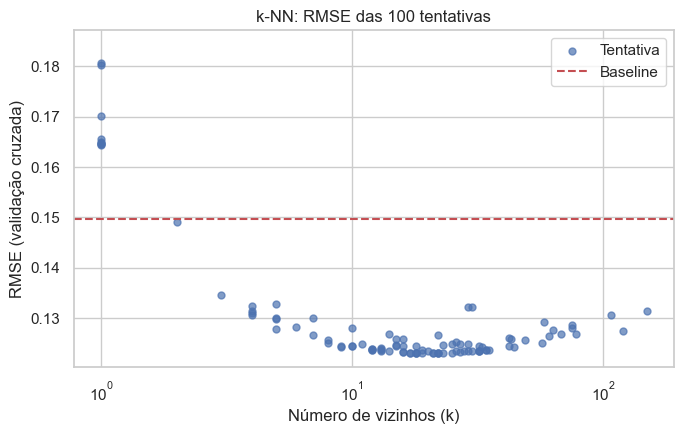

In [24]:
resume_estudo(estudo_knn, "k-NN", "num_vizinhos", "Número de vizinhos (k)", escala_log=True)

**Análise do k-NN.** O melhor k-NN atingiu RMSE de 0,1231 ± 0,0042 na validação cruzada (17,8% abaixo do baseline), com 17 vizinhos, pesos por distância, distância quase igual à de Manhattan (p ≈ 1,05) e sem PCA. O hiperparâmetro que mais pesa é de longe o número de vizinhos (88% da importância): com poucos vizinhos o modelo é ruidoso e com muitos suaviza demais, e os demais hiperparâmetros fazem pouca diferença (4% ou menos cada). A distância de Manhattan pode ter sido preferida por ser menos sensível a valores extremos, mas não testei essa explicação. Provavelmente também importa que as 30 colunas do one-hot do tipo de tumor entram no cálculo da distância, então tumores do mesmo tipo tendem a ser vizinhos, o que dá ao k-NN uma "média por tipo" refinada pelos atributos genômicos. O PCA foi usado em 26 das 100 tentativas, com RMSE mediano pior (0,1297 contra 0,1242 sem PCA).

#### 4.4.2 Regressão linear polinomial

In [25]:
estudo_lin = executa_estudo("tiamat_linear_polinomial", cria_instancia_modelo_lin, TENTATIVAS_INICIAIS_LIN)
resultados["Regressão linear polinomial"] = {"estudo": estudo_lin, "cria": cria_instancia_modelo_lin}

Tentativas completas: 100 | combinações diferentes: 100
Número do melhor trial: 4
RMSE na validação cruzada: 0.1213 ± 0.0040
Parâmetros do melhor trial: {'grau_polinomio': 2, 'apenas_interacoes': False, 'fracao_atributos': 0.9714143595538947}
Importância dos hiperparâmetros: {'fracao_atributos': 0.74, 'grau_polinomio': 0.21, 'apenas_interacoes': 0.05}
ATENÇÃO: fracao_atributos = 0.9714 está na borda do intervalo [0.05, 1.0]


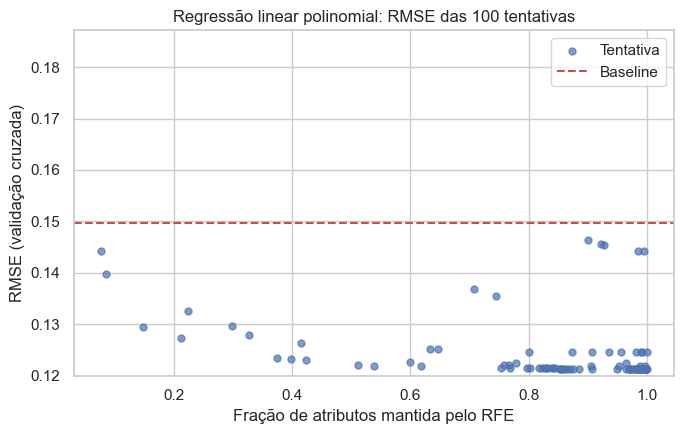

In [26]:
resume_estudo(estudo_lin, "Regressão linear polinomial", "fracao_atributos", "Fração de atributos mantida pelo RFE")

**Análise da regressão linear polinomial.** O melhor modelo atingiu RMSE de 0,1213 ± 0,0040 na validação cruzada (19% abaixo do baseline), com polinômio de grau 2 (quadrados e produtos entre atributos, `apenas_interacoes = False`) e RFE mantendo 97% das colunas (cerca de 92 de 95). Comparando os graus: o grau 1, que é a regressão linear múltipla comum, chegou a 0,1245; o grau 2 melhorou esse valor em 2,6%, o que indica que há alguma curvatura e interação entre atributos que um modelo puramente aditivo não captura; e o grau 3 só ficou competitivo com RFE (melhor RMSE de 0,1224, mas mediana de 0,1325 nas 13 tentativas com RFE).

O grau 3 gera 315 colunas para cerca de 6,7 mil pacientes em cada partição de treino, e o modelo sobreajusta: a única tentativa de grau 3 sem RFE teve RMSE de 0,1443. É aí que a seleção por RFE ajuda. No grau 2, ao contrário, o RMSE mediano foi o mesmo com e sem RFE (0,1213), e por isso o melhor valor de `fracao_atributos` (0,97) ficou próximo do limite superior do intervalo, ou seja, quase sem seleção (o aviso de borda acima). A importância alta atribuída pelo Optuna à fração de atributos (0,73) vem provavelmente das tentativas de grau 3, em que o RFE muda bastante o resultado, mas não verifiquei isso. Já o hiperparâmetro `apenas_interacoes` teve importância baixa (0,05).

#### 4.4.3 Árvore de decisão

In [27]:
estudo_dt = executa_estudo("tiamat_arvore", cria_instancia_modelo_dt, TENTATIVAS_INICIAIS_DT)
resultados["Árvore de decisão"] = {"estudo": estudo_dt, "cria": cria_instancia_modelo_dt}

Tentativas completas: 100 | combinações diferentes: 100
Número do melhor trial: 83
RMSE na validação cruzada: 0.1289 ± 0.0033
Parâmetros do melhor trial: {'criterio': 'friedman_mse', 'profundidade_max': 16, 'min_exemplos_split': 180, 'min_exemplos_folha': 8, 'fracao_max_atributos': 0.710204664643082, 'ccp_alpha': 1.7092494228390472e-07}
Importância dos hiperparâmetros: {'ccp_alpha': 0.49, 'fracao_max_atributos': 0.3, 'profundidade_max': 0.14, 'min_exemplos_split': 0.04, 'min_exemplos_folha': 0.03, 'criterio': 0.01}
ATENÇÃO: min_exemplos_split = 180 está na borda do intervalo [2, 200]


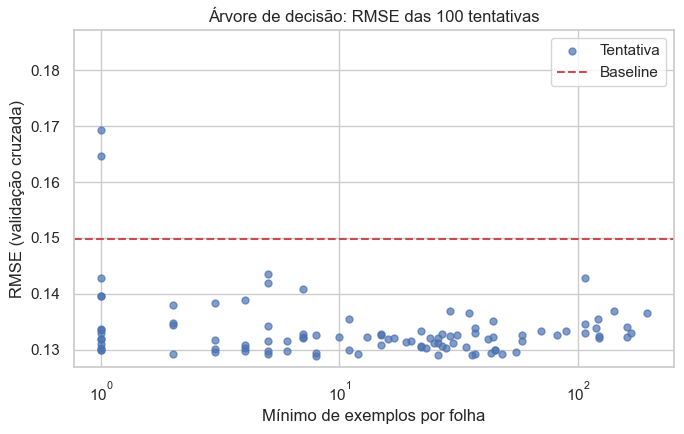

In [28]:
resume_estudo(estudo_dt, "Árvore de decisão", "min_exemplos_folha", "Mínimo de exemplos por folha", escala_log=True)

**Análise da árvore de decisão.** A árvore teve o pior desempenho entre os cinco: RMSE de 0,1289 ± 0,0033 na validação cruzada, ainda 14% melhor que o baseline. O melhor modelo usou o critério `friedman_mse`, profundidade máxima de 16, mínimo de 8 exemplos por folha, mínimo de 180 exemplos para dividir um nó e 71% dos atributos por divisão. O hiperparâmetro de maior importância foi o `ccp_alpha` (0,49), seguido da fração de atributos (0,26) e da profundidade (0,15). Como o melhor `ccp_alpha` foi muito pequeno (1,7e-7, quase sem poda), a importância provavelmente vem de tentativas com poda forte, que pioram o erro, mas não verifiquei isso. O melhor `min_exemplos_split` (180) ficou perto do limite superior do intervalo (200), então ampliar o intervalo é um próximo passo possível. Uma árvore única tende a ter alta variância: pequenas mudanças nos dados mudam as divisões, e mesmo com folhas grandes ela fica atrás dos demais algoritmos. A melhora da floresta sobre a árvore, vista a seguir, mostra o quanto essa variância custa.

#### 4.4.4 Floresta aleatória

In [29]:
estudo_rf = executa_estudo("tiamat_floresta", cria_instancia_modelo_rf, TENTATIVAS_INICIAIS_RF)
resultados["Floresta aleatória"] = {"estudo": estudo_rf, "cria": cria_instancia_modelo_rf}

Tentativas completas: 100 | combinações diferentes: 100
Número do melhor trial: 80
RMSE na validação cruzada: 0.1183 ± 0.0034
Parâmetros do melhor trial: {'num_arvores': 290, 'profundidade_max': 20, 'min_exemplos_folha': 1, 'fracao_max_atributos': 0.3962360986181421, 'fracao_amostras': 0.9574959508946459}
Importância dos hiperparâmetros: {'profundidade_max': 0.76, 'min_exemplos_folha': 0.18, 'fracao_max_atributos': 0.04, 'num_arvores': 0.02, 'fracao_amostras': 0.01}
ATENÇÃO: num_arvores = 290 está na borda do intervalo [50, 300]
ATENÇÃO: min_exemplos_folha = 1 está na borda do intervalo [1, 50]


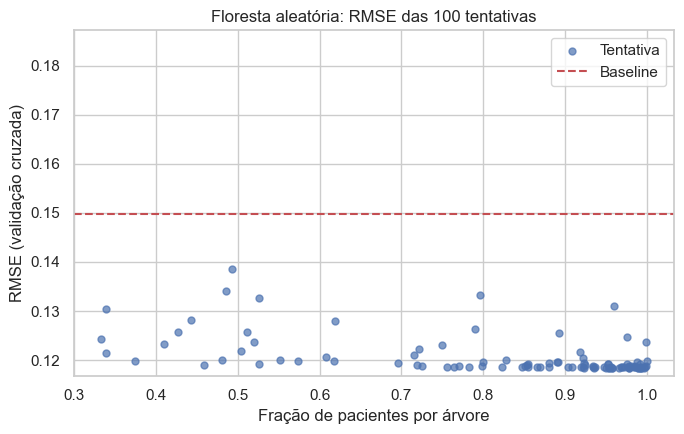

In [30]:
resume_estudo(estudo_rf, "Floresta aleatória", "fracao_amostras", "Fração de pacientes por árvore")

**Análise da floresta aleatória.** A floresta reduziu o RMSE para 0,1183 ± 0,0034 na validação cruzada (21% abaixo do baseline e 8,2% melhor que a árvore única). O melhor modelo usou 290 árvores, profundidade 20, folhas de 1 exemplo, 40% dos atributos por divisão e 96% dos pacientes por árvore. É um arranjo típico de floresta: árvores profundas e individualmente sobreajustadas, mas pouco parecidas entre si (poucos atributos sorteados por divisão), de modo que a média cancela boa parte do erro. Os hiperparâmetros mais importantes foram a profundidade máxima (0,74) e o tamanho mínimo da folha (0,21), isto é, os que controlam a complexidade de cada árvore. Duas observações sobre os limites do espaço de busca: o número de árvores (290, de no máximo 300), que limitei por custo computacional, poderia ser ampliado com um ganho provavelmente pequeno, e a folha de 1 exemplo é o menor valor possível, então não há como ampliar nesse sentido.

#### 4.4.5 Gradient Boosting

In [31]:
estudo_gb = executa_estudo("tiamat_boosting", cria_instancia_modelo_gb, TENTATIVAS_INICIAIS_GB)
resultados["Gradient Boosting"] = {"estudo": estudo_gb, "cria": cria_instancia_modelo_gb}

Tentativas completas: 100 | combinações diferentes: 100
Número do melhor trial: 86
RMSE na validação cruzada: 0.1159 ± 0.0035
Parâmetros do melhor trial: {'taxa_aprendizado': 0.05756904860428127, 'num_iteracoes': 272, 'max_folhas': 14, 'min_exemplos_folha': 19, 'regularizacao_l2': 0.06826649904534499}
Importância dos hiperparâmetros: {'min_exemplos_folha': 0.44, 'taxa_aprendizado': 0.23, 'max_folhas': 0.17, 'num_iteracoes': 0.12, 'regularizacao_l2': 0.04}


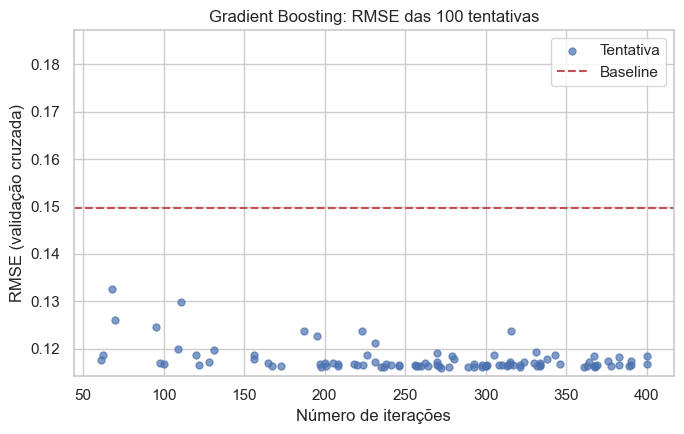

In [32]:
resume_estudo(estudo_gb, "Gradient Boosting", "num_iteracoes", "Número de iterações")

**Análise do Gradient Boosting.** O Gradient Boosting teve o melhor desempenho: RMSE de 0,1159 ± 0,0035 na validação cruzada (23% abaixo do baseline), com taxa de aprendizado de 0,058, 272 iterações, árvores pequenas (14 folhas, num intervalo de 8 a 64), mínimo de 19 exemplos por folha e regularização L2 de 0,068. As árvores pequenas indicam que interações de baixa ordem (poucos atributos combinados) são suficientes, e que o ganho do boosting vem de reduzir o viés aos poucos, em vez de aprender regras complexas de uma vez. O tamanho mínimo da folha foi o hiperparâmetro de maior importância (0,42), seguido da taxa de aprendizado (0,21) e do número de folhas (0,20). Nenhum melhor valor ficou na borda do intervalo (não houve aviso), sinal de que o espaço de busca cobriu bem a região do ótimo.

## 5. Resultados e discussão

### 5.1 Comparação dos modelos

Cada algoritmo foi treinado de novo com a melhor combinação de hiperparâmetros, usando todo o conjunto de treino, e avaliado **uma única vez** no conjunto de teste. A escolha do melhor modelo usa apenas o RMSE da validação cruzada, nunca o teste.

In [33]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

linhas = []

baseline.fit(X_treino, y_treino)
previsao = baseline.predict(X_teste)
linhas.append({
    "Algoritmo": "Baseline (média)",
    "RMSE CV": rmse_baseline.mean(), "Desvio CV": rmse_baseline.std(),
    "RMSE teste": root_mean_squared_error(y_teste, previsao),
    "MAE teste": mean_absolute_error(y_teste, previsao),
    "R² teste": r2_score(y_teste, previsao),
})

previsoes_teste = {"Baseline (média)": previsao}
modelos_finais = {}

for nome, info in resultados.items():
    modelo = info["cria"](info["estudo"].best_trial)
    modelo.fit(X_treino, y_treino)
    previsao = modelo.predict(X_teste)
    modelos_finais[nome] = modelo
    previsoes_teste[nome] = previsao
    linhas.append({
        "Algoritmo": nome,
        "RMSE CV": info["estudo"].best_value,
        "Desvio CV": info["estudo"].best_trial.user_attrs["rmse_desvio"],
        "RMSE teste": root_mean_squared_error(y_teste, previsao),
        "MAE teste": mean_absolute_error(y_teste, previsao),
        "R² teste": r2_score(y_teste, previsao),
    })

tabela = pd.DataFrame(linhas).set_index("Algoritmo").sort_values("RMSE CV")
tabela.round(4)

,RMSE CV,Desvio CV,RMSE teste,MAE teste,R² teste
Algoritmo,,,,,
Gradient Boosting,0.1159,0.0035,0.1167,0.0895,0.4001
Floresta aleatória,0.1183,0.0034,0.1198,0.0919,0.3686
Regressão linear polinomial,0.1213,0.0040,0.1221,0.0938,0.3435
k-NN,0.1231,0.0042,0.1241,0.0939,0.3223
Árvore de decisão,0.1289,0.0033,0.1297,0.0988,0.2593
Baseline (média),0.1497,0.0046,0.1507,0.1208,-0.0001


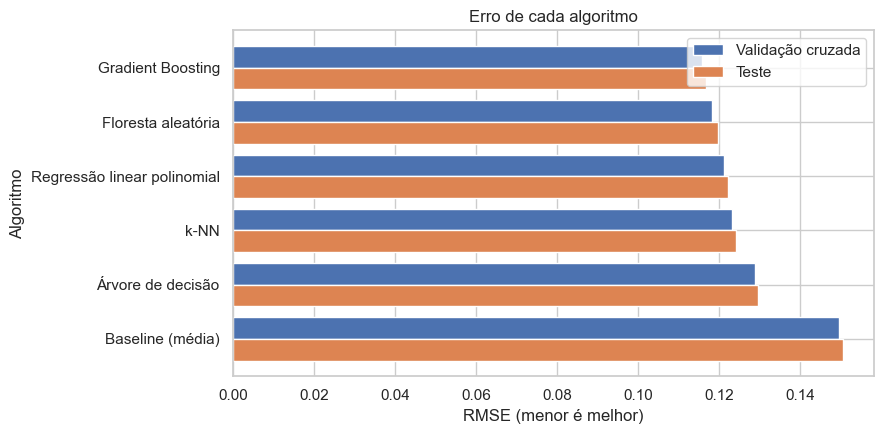

In [34]:
fig, eixo = plt.subplots(figsize=(9, 4.5))
posicao = np.arange(len(tabela))
eixo.barh(posicao - 0.2, tabela["RMSE CV"], 0.4, label="Validação cruzada", color="C0")
eixo.barh(posicao + 0.2, tabela["RMSE teste"], 0.4, label="Teste", color="C1")
eixo.set_yticks(posicao, tabela.index)
eixo.invert_yaxis()
eixo.set(xlabel="RMSE (menor é melhor)", ylabel="Algoritmo", title="Erro de cada algoritmo")
eixo.legend()
plt.tight_layout()
plt.show()

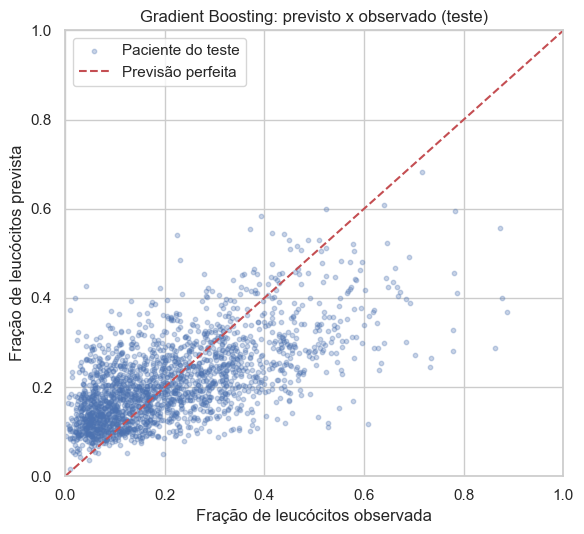

In [35]:
nome_melhor = tabela.drop("Baseline (média)").index[0]

fig, eixo = plt.subplots(figsize=(6, 5.5))
eixo.scatter(y_teste, previsoes_teste[nome_melhor], s=10, alpha=0.3, label="Paciente do teste")
eixo.plot([0, 1], [0, 1], color="C3", ls="--", label="Previsão perfeita")
eixo.set(xlabel="Fração de leucócitos observada", ylabel="Fração de leucócitos prevista",
         title=f"{nome_melhor}: previsto x observado (teste)", xlim=(0, 1), ylim=(0, 1))
eixo.legend()
plt.tight_layout()
plt.show()

In [36]:
# Referências complementares (ajudam a medir o quanto os atributos genômicos acrescentam)

# (a) Baseline por tipo de câncer: prevê a média do alvo do tipo, sem usar nenhum atributo genômico
media_por_tipo = df_treino.groupby(ATRIBUTO_CATEGORICO)[TARGET].mean()
previsao_tipo = df_teste[ATRIBUTO_CATEGORICO].map(media_por_tipo)
print("Baseline por tipo de câncer:  "
      f"RMSE = {root_mean_squared_error(y_teste, previsao_tipo):.4f} | R² = {r2_score(y_teste, previsao_tipo):.3f}")

# (b) Gradient Boosting sem o tipo de câncer (mesmos hiperparâmetros do melhor modelo; só atributos genômicos)
from sklearn.ensemble import HistGradientBoostingRegressor

p = estudo_gb.best_trial.params
modelo_sem_tipo = HistGradientBoostingRegressor(
    learning_rate=p["taxa_aprendizado"], max_iter=p["num_iteracoes"], max_leaf_nodes=p["max_folhas"],
    min_samples_leaf=p["min_exemplos_folha"], l2_regularization=p["regularizacao_l2"],
    early_stopping=False, random_state=SEMENTE_ALEATORIA,
)
modelo_sem_tipo.fit(X_treino[ATRIBUTOS_NUMERICOS], y_treino)
previsao_sem_tipo = modelo_sem_tipo.predict(X_teste[ATRIBUTOS_NUMERICOS])
print("Gradient Boosting sem tipo:   "
      f"RMSE = {root_mean_squared_error(y_teste, previsao_sem_tipo):.4f} | R² = {r2_score(y_teste, previsao_sem_tipo):.3f}")

Baseline por tipo de câncer:  RMSE = 0.1356 | R² = 0.190
Gradient Boosting sem tipo:   RMSE = 0.1260 | R² = 0.301


**Comparação dos modelos.** Os cinco algoritmos ficaram bem melhores que o baseline. No teste, o RMSE foi de 0,1167 (Gradient Boosting, R² de 0,40), 0,1198 (floresta, 0,37), 0,1221 (regressão linear polinomial, 0,34), 0,1241 (k-NN, 0,32) e 0,1297 (árvore, 0,26), contra 0,1507 do baseline (R² ≈ 0). A ordem dos algoritmos é a mesma na validação cruzada e no teste, e os erros diferem em no máximo 0,0015, o que indica que a escolha de hiperparâmetros não sobreajustou a validação cruzada e que não houve vazamento do teste para a escolha do modelo.

Quanto às diferenças, o desvio entre partições da validação cruzada é de 0,003 a 0,005, e diferenças menores que isso não são conclusivas. O Gradient Boosting e a floresta (diferença de 0,0024 na validação cruzada) e a regressão linear polinomial e o k-NN (0,0018) não são distinguíveis. O Gradient Boosting é cerca de 0,005 melhor que a regressão linear polinomial, pouco mais de um desvio, e a árvore única fica por último, com 0,006 a 0,008 de erro a mais que o k-NN e a regressão linear. Em resumo, os conjuntos de árvores são os melhores, a regressão linear polinomial e o k-NN ficam no meio, praticamente empatados, e a árvore única fica por último. Um resultado notável é que um modelo linear com termos quadráticos chega perto da floresta, o que sugere que a relação entre o genoma e a infiltração é, em grande parte, suave e de baixa ordem.

**Quanto os atributos genômicos acrescentam.** Para medir isso, calculei duas referências. Um baseline que usa só o tipo de câncer (a média do alvo de cada tipo, sem nenhum atributo genômico) já obtém RMSE de 0,1356 e R² de 0,19, e o melhor modelo, com os atributos genômicos, chega a R² de 0,40, ou seja, mais que **dobra** o poder explicativo. Por outro lado, o mesmo Gradient Boosting sem o tipo de câncer (só atributos genômicos) obtém RMSE de 0,1260 e R² de 0,30 (com hiperparâmetros otimizados para o modelo completo, o que o desfavorece um pouco). Os dois conjuntos de informação, portanto, se sobrepõem em parte, mas nenhum substitui o outro. O gráfico de previsto contra observado do melhor modelo mostra o padrão típico de regressão à média: no teste, os 110 pacientes com fração observada acima de 0,5 têm previsão média de apenas cerca de 0,36 (observado médio de cerca de 0,59), e os 210 com fração abaixo de 0,05 têm previsão média de cerca de 0,14 (observado médio de cerca de 0,03). Uma parcela grande da variância continua sem explicação (60%).

### 5.2 Efeito da redução de dimensionalidade

O Optuna decidiu, para o k-NN, se aplicava ou não PCA aos atributos numéricos e com quantos componentes, e, para a regressão linear, que fração dos atributos manter pelo RFE (seleção de atributos da aula 8.1). A comparação abaixo mostra se a redução ajudou.

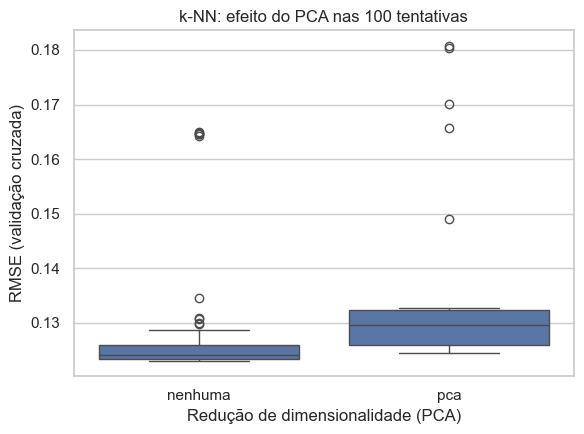

k-NN:
                count     min  median
params_reducao                       
nenhuma            74  0.1231  0.1242
pca                26  0.1244  0.1297
Melhor tentativa com PCA usou 10 componentes (RMSE = 0.1244)

Regressão linear polinomial:
                               count     min  median
params_grau_polinomio selecao                       
1                     com RFE     12  0.1245  0.1249
                      sem RFE      3  0.1245  0.1245
2                     com RFE     51  0.1213  0.1213
                      sem RFE     20  0.1213  0.1213
3                     com RFE     13  0.1224  0.1325
                      sem RFE      1  0.1443  0.1443


In [37]:
# k-NN: efeito do PCA
t = resultados["k-NN"]["estudo"].trials_dataframe()

fig, eixo = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=t, x="params_reducao", y="value", order=["nenhuma", "pca"], ax=eixo, color="C0")
eixo.set(xlabel="Redução de dimensionalidade (PCA)", ylabel="RMSE (validação cruzada)",
         title="k-NN: efeito do PCA nas 100 tentativas")
plt.tight_layout()
plt.show()

print("k-NN:")
print(t.groupby("params_reducao")["value"].agg(["count", "min", "median"]).round(4))
pca_t = t[t["params_reducao"] == "pca"]
melhor_pca = pca_t.loc[pca_t["value"].idxmin()]
print(f"Melhor tentativa com PCA usou {int(melhor_pca['params_n_componentes'])} componentes "
      f"(RMSE = {melhor_pca['value']:.4f})")

# Regressão linear: efeito da seleção de atributos (RFE) e do grau do polinômio
t = resultados["Regressão linear polinomial"]["estudo"].trials_dataframe()
t["selecao"] = np.where(t["params_fracao_atributos"] >= 0.99, "sem RFE", "com RFE")

print("\nRegressão linear polinomial:")
print(t.groupby(["params_grau_polinomio", "selecao"])["value"].agg(["count", "min", "median"]).round(4))

**Análise da redução de dimensionalidade.** No k-NN, o Optuna usou PCA em 26 das 100 tentativas, e elas foram piores: melhor RMSE de 0,1244 contra 0,1231 sem PCA, e mediana de 0,1297 contra 0,1242. O melhor k-NN com PCA usou 10 componentes, ou seja, nenhuma redução, apenas uma rotação dos atributos. Na regressão linear polinomial, a seleção de atributos por RFE só foi útil para corrigir o excesso de colunas criado pelo próprio polinômio: no grau 3, o RMSE foi de 0,1443 (única tentativa sem RFE) para até 0,1224 com RFE (mas com mediana de 0,1325, então a fração de colunas mantida precisa ser bem escolhida); nos graus 1 e 2, o RMSE foi o mesmo com e sem RFE (0,1245 e 0,1213).

Em resumo, **reduzir dimensionalidade não melhorou os modelos que já estavam bem comportados**. Isso é coerente com a análise exploratória: com apenas 10 atributos numéricos e pouca redundância (exceto o grupo das mutações), não há muito ruído a eliminar, e como o PCA retém variância e não informação sobre o alvo, descartar componentes pequenos pode jogar fora sinal útil. A seleção só ajudou quando o próprio modelo criou atributos demais.

**Limite dessa análise.** O conjunto tem 11 atributos originais (40 colunas após o one-hot), abaixo dos 20 atributos exigidos para a estratégia de redução de dimensionalidade valer como item de pontuação. O RFE da regressão linear opera sobre até 315 colunas, mas elas são combinações dos mesmos 10 atributos numéricos e do tipo de câncer, e não atributos novos. Por isso trato este experimento como uma análise, e não como o cumprimento do critério.

### 5.3 Explicação do melhor modelo

Para entender o que o melhor modelo (escolhido pelo RMSE da validação cruzada) aprendeu, usei a **importância por permutação**: embaralha-se uma coluna do conjunto de teste por vez e mede-se o quanto o erro aumenta, e quanto maior o aumento, mais o modelo depende daquela coluna. Como o embaralhamento é feito nas colunas originais, o tipo de tumor aparece como um único atributo. Em seguida, os gráficos de dependência parcial mostram como a previsão média muda com cada atributo numérico mais importante. Os gráficos de dependência parcial usam 2.000 pacientes do treino que têm valor nos três atributos analisados, porque a função não aceita valores faltantes no atributo que ela varre.

Melhor modelo pelo RMSE da validação cruzada: Gradient Boosting


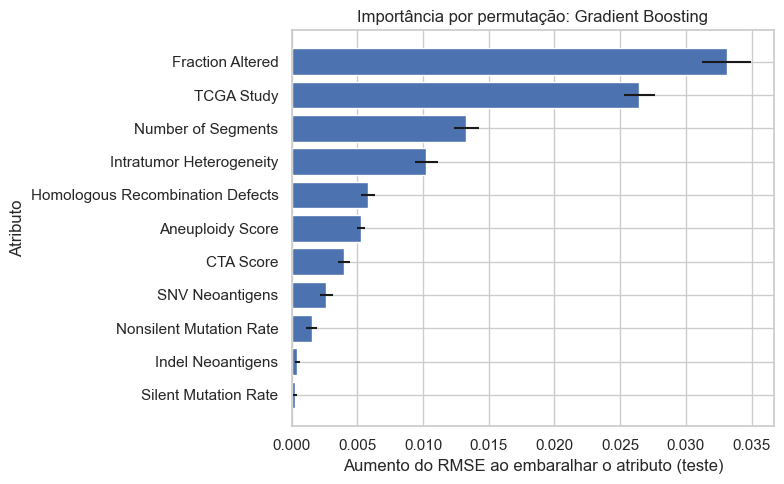

In [38]:
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

nome_melhor = tabela.drop("Baseline (média)").index[0]
modelo_melhor = modelos_finais[nome_melhor]
print("Melhor modelo pelo RMSE da validação cruzada:", nome_melhor)

perm = permutation_importance(
    modelo_melhor, X_teste, y_teste,
    scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEMENTE_ALEATORIA,
)
importancia = pd.DataFrame({"media": perm.importances_mean, "desvio": perm.importances_std},
                           index=ATRIBUTOS).sort_values("media")

fig, eixo = plt.subplots(figsize=(8, 5))
eixo.barh(importancia.index, importancia["media"], xerr=importancia["desvio"], color="C0")
eixo.set(xlabel="Aumento do RMSE ao embaralhar o atributo (teste)", ylabel="Atributo",
         title=f"Importância por permutação: {nome_melhor}")
plt.tight_layout()
plt.show()

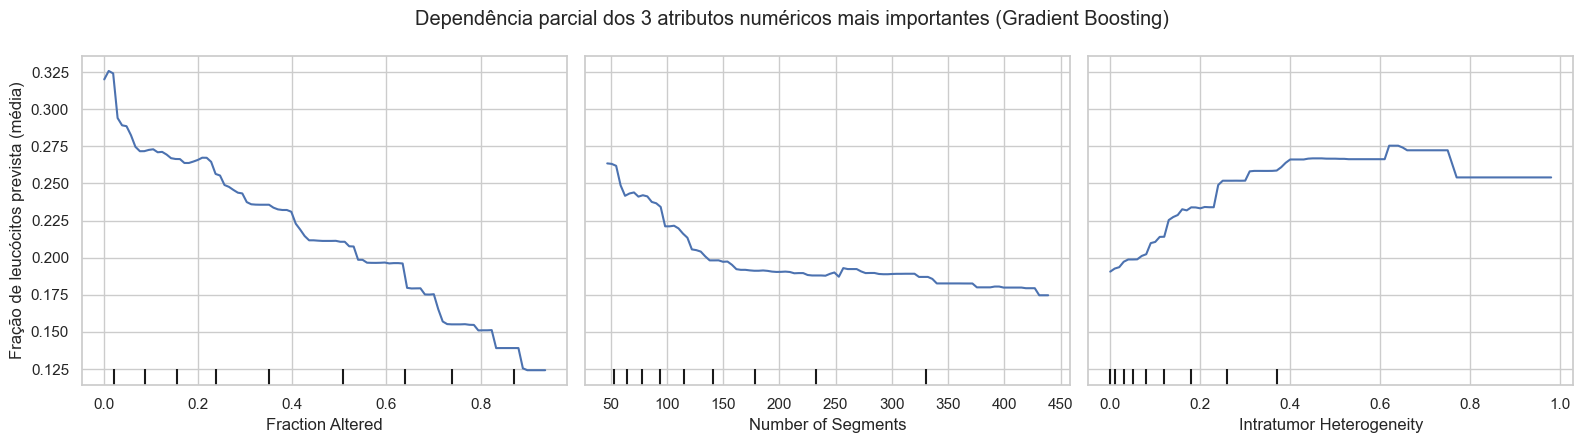

In [39]:
principais = [a for a in importancia.index[::-1] if a in ATRIBUTOS_NUMERICOS][:3]

# A dependência parcial varre uma grade de valores de cada atributo e não aceita faltantes nele,
# então a amostra usa só pacientes com valor nesses 3 atributos (os demais atributos podem faltar)
amostra = X_treino.dropna(subset=principais).sample(2000, random_state=SEMENTE_ALEATORIA)

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
PartialDependenceDisplay.from_estimator(modelo_melhor, amostra, principais, kind="average", ax=eixos)
for eixo, atributo in zip(eixos, principais):
    eixo.set_xlabel(atributo)
for eixo in eixos[1:]:
    eixo.set_ylabel("")
eixos[0].set_ylabel("Fração de leucócitos prevista (média)")
fig.suptitle(f"Dependência parcial dos 3 atributos numéricos mais importantes ({nome_melhor})")
plt.tight_layout()
plt.show()

# Célula corrigida com ajuda da IA (revisão final) *****

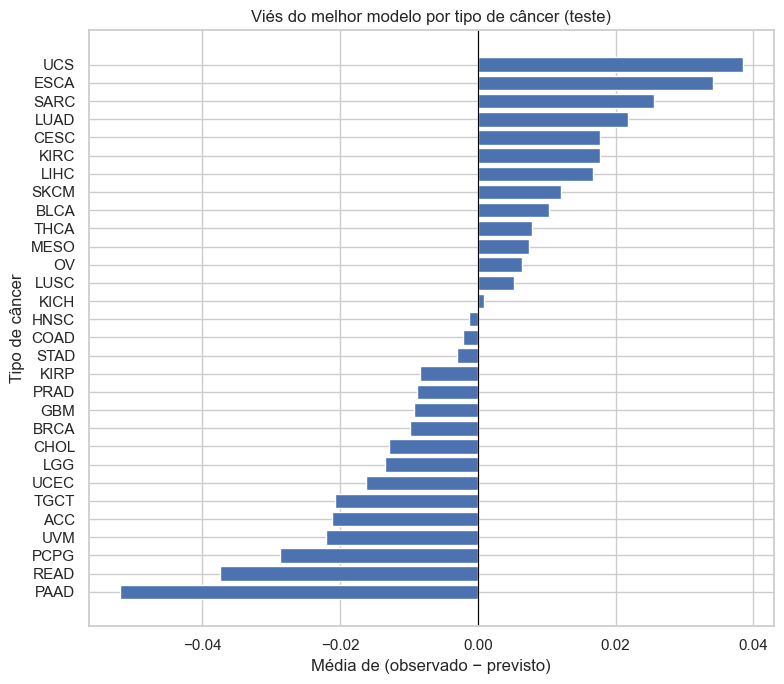

In [40]:
residuos = pd.DataFrame({
    "Tipo de câncer": df_teste[ATRIBUTO_CATEGORICO].values,
    "Resíduo": y_teste.values - previsoes_teste[nome_melhor],
})
# Média (e não mediana): o erro do alvo é assimétrico, e a mediana do resíduo fica negativa em quase todos os tipos
media_residuo = residuos.groupby("Tipo de câncer")["Resíduo"].mean().sort_values()

fig, eixo = plt.subplots(figsize=(8, 7))
eixo.barh(media_residuo.index, media_residuo.values, color="C0")
eixo.axvline(0, color="black", lw=0.8)
eixo.set(xlabel="Média de (observado − previsto)", ylabel="Tipo de câncer",
         title="Viés do melhor modelo por tipo de câncer (teste)")
plt.tight_layout()
plt.show()

# Célula corrigida com ajuda da IA (revisão final) *****

**Importância por permutação (Gradient Boosting, teste).** O aumento do RMSE ao embaralhar cada atributo foi de cerca de: Fraction Altered +0,032, TCGA Study +0,025, Number of Segments +0,013, Intratumor Heterogeneity +0,010, HRD +0,006, Aneuploidy Score +0,005, CTA Score +0,004, SNV Neoantigens +0,002, Nonsilent Mutation Rate +0,001, Silent Mutation Rate e Indel Neoantigens +0,0004 (desvios de no máximo 0,002 entre as 10 repetições, então a ordem dos primeiros é estável). Os dois atributos mais importantes são a **fração do genoma alterada** e o **tipo de câncer**, seguidos de outra medida de alteração de cópias. Isso coincide com a análise exploratória, em que as medidas de alteração de cópias tinham as associações mais consistentes dentro dos tipos.

Chama a atenção que as medidas de carga mutacional, o biomarcador clássico de imunoterapia, aparecem com importância baixa. Há duas razões possíveis: dentro de cada tipo a correlação delas com o alvo é praticamente nula (visto acima) e, como as três variáveis de mutação são quase redundantes (correlação ≥ 0,92), embaralhar uma delas pouco afeta o modelo porque as outras duas compensam. Por isso a importância por permutação subestima o efeito do grupo, e não devo concluir que a carga mutacional é irrelevante.

**Dependência parcial.** A previsão cai de forma quase contínua com a fração alterada do genoma, de cerca de 0,31 (quase sem alterações) a cerca de 0,12 (mais de 90% do genoma alterado). Com o número de segmentos, ela cai de cerca de 0,27 (poucos segmentos) para cerca de 0,19 por volta de 150 a 200 segmentos, e depois cai devagar, até cerca de 0,17. Com a heterogeneidade intratumoral, ela sobe de cerca de 0,19 (sem heterogeneidade) até um patamar de 0,26 a 0,28 a partir de 0,4, e a queda no fim da faixa (acima de 0,75) deve ser vista com cautela, pois há pouquíssimos pacientes com valores tão altos (as marcas no eixo horizontal mostram que 90% dos pacientes ficam abaixo de cerca de 0,4). Em conjunto, os padrões são compatíveis com a hipótese de que tumores com o genoma muito rearranjado são menos infiltrados, mas são associações observacionais e não provam causa.

**Viés por tipo de câncer.** O gráfico mostra a média de (observado − previsto) em cada tipo, e não a mediana, porque o erro é assimétrico: a mediana do resíduo é negativa (cerca de −0,017) mesmo com média praticamente zero, o que daria a falsa impressão de que o modelo superestima quase todos os tipos. Na maioria dos tipos o viés médio é pequeno (até 0,03 em módulo em 26 dos 30 tipos). O modelo prevê valores altos demais para PAAD (cerca de −0,05) e READ (cerca de −0,03), e baixos demais para ESCA (cerca de +0,04) e UCS (cerca de +0,04). Alguns tipos têm poucos pacientes no teste (UCS, 11; CHOL, 7; KICH, 13), então os resíduos deles são pouco confiáveis.

## 6. Conclusões e principais aprendizados

**Resposta à pergunta.** As características genômicas conseguem prever o grau de infiltração imune **em parte**. O melhor modelo (Gradient Boosting) reduziu o RMSE de 0,151 (baseline) para 0,117 no teste (23% menos erro) e explica cerca de 40% da variância. Desse total, o tipo de câncer sozinho já explica 19%, e os atributos genômicos sem o tipo explicam 30%, então os dois se complementam em parte. Cerca de 60% da variação continua sem explicação, o que é plausível, já que a infiltração depende também de fatores que não estão no genoma do tumor (como a expressão gênica e o microambiente) e a própria fração de leucócitos é uma estimativa com ruído.

**O que aprendi sobre os algoritmos.** Os conjuntos de árvores (Gradient Boosting, 0,1167; floresta, 0,1198) foram os melhores, seguidos de perto pela regressão linear polinomial (0,1221) e pelo k-NN (0,1241), com a árvore única por último (0,1297). A floresta melhorou a árvore única em cerca de 8% (na validação cruzada), mostrando o custo da variância, e o boosting com árvores pequenas (14 folhas) foi o melhor, sugerindo que interações de baixa ordem bastam. A regressão linear com termos quadráticos superou a regressão linear simples (RMSE na validação cruzada de 0,1213 contra 0,1245), enquanto o grau 3 só ficou competitivo com seleção de atributos, o que indica que a relação entre genoma e infiltração é em boa parte suave e de baixa ordem. As diferenças entre os dois melhores, e entre a regressão linear e o k-NN, são pequenas demais para serem conclusivas.

**O que aprendi sobre os dados.** Os atributos que mais pesam são as medidas de alteração de cópias do DNA (fração alterada do genoma e número de segmentos) e o tipo de câncer. A carga mutacional correlaciona com a infiltração quando se misturam os tipos, mas quase nada dentro de cada tipo, um exemplo claro do paradoxo de Simpson, que só apareceu porque examinei as correlações por tipo. A redução de dimensionalidade só ajudou para corrigir o excesso de atributos do polinômio de grau 3, e não melhorou os demais modelos.

**Aprendizados de método.** Dividir os dados antes da análise exploratória, manter todas as transformações dentro do pipeline e usar o teste uma única vez deram resultados coerentes: o erro na validação cruzada e no teste diferiu em no máximo 0,0015 para todos os modelos. Também aprendi que conferir o gráfico com o resultado numérico evita conclusões erradas: a mediana do resíduo sugeria um viés que a média mostrou não existir.

**Limitações.** (1) O conjunto tem 11 atributos originais, então a análise de redução de dimensionalidade não cumpre o critério de 20 atributos. (2) Limitei alguns intervalos de hiperparâmetros por custo computacional, e alguns melhores valores ficaram perto das bordas (número de árvores da floresta, 290 de 300, e mínimo de exemplos para dividir da árvore, 180 de 200). (3) Três tipos de câncer (DLBC, LAML e THYM) ficaram de fora por não terem o alvo. (4) Os resultados são associações em dados observacionais e não provam causalidade. (5) Não calculei intervalos de confiança para as métricas no teste, e por isso as diferenças pequenas entre modelos não são conclusivas.

**Próximos passos.** Ampliar os intervalos de busca nos casos que ficaram na borda, testar interações explícitas entre o tipo de tumor e os atributos genômicos (ou um modelo por tipo), incluir atributos de expressão gênica de outras fontes e usar SHAP para uma explicação por paciente.

## 8. Referências

- THORSSON, V. et al. The Immune Landscape of Cancer. *Immunity*, v. 48, n. 4, p. 812-830, 2018. Dados: Tabela S1 (*PanImmune Feature Matrix*).
- CASSAR, D. R. *ATP-203 – Aprendizado de Máquina*. Material de aula (notebooks e slides), Ilum Escola de Ciência, 2026.
- FACELI, K. et al. *Inteligência Artificial: uma abordagem de Aprendizado de Máquina*. 2. ed. Rio de Janeiro: LTC, 2021.
- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011.
- AKIBA, T. et al. Optuna: A Next-generation Hyperparameter Optimization Framework. In: *Proceedings of the 25th ACM SIGKDD*, 2019.
- ANTHROPIC. *Claude* (assistente de IA), usado conforme descrito na seção abaixo.

### Descrição do uso de IA neste trabalho

Usei o assistente de IA Claude (Anthropic) em diferentes etapas deste trabalho:

- **Escolha da base de dados:** para sugerir bases ligadas à imunologia, à imunoterapia e ao câncer compatíveis com os requisitos do projeto, e para localizar a origem da Tabela S1 do artigo de Thorsson et al. (2018).
- **Análise prévia dos dados:** para explicar o significado de alguns atributos complexos e ajudar a identificar problemas na base que eu pudesse ter deixado passar (colunas duplicadas, valores faltantes, relações entre atributos).
- **Planejamento:** para discutir a escolha do alvo, do baseline e dos algoritmos, o risco de vazamento de dados e como cumprir os critérios do enunciado.
- **Texto:** para corrigir e revisar as explicações e as análises em markdown.
- **Gráficos:** ajuda na construção de alguns dos gráficos mais complexos.
- **Revisão final:** para executar o notebook de cima para baixo, corrigir erros de código (o gráfico de dependência parcial, que não funcionava com atributos com valores faltantes, e o gráfico de erro por tipo de câncer, que passou a usar a média do resíduo no lugar da mediana) e atualizar os textos para que os números citados coincidam com as saídas das células.

OBS: as células de código feitas com ajuda da IA estão sinalizadas